# Notebook 4 — `4_flood_eda`

## Overview

**Purpose:** Exploratory descriptive analysis and visualisation of the compiled BNPB flood records (2016–2025), establishing the empirical basis for the multidimensional Flood Severity Index developed in Notebooks 5–6.

**Dataset:** BNPB Indonesian flood events, 2016–2025 (13,030 records; 502 regencies with recorded events, of 514 total; 38 provinces). Regency-level analyses use the cumulative seven-variable structure (event count plus six impact variables) that is the input to the k-means typology in Notebooks 5–6.

## Data requirements

Download the following data before running the notebook. Raw data are not redistributed in this repository in accordance with the providers' terms of use.

| Dataset | Source | Required files | Directory |
|---|---|---|---|
| Compiled flood records | Produced by Notebook 1 | `1_bencana_compiled_with_bps.xlsx` | `data/processed/` |
| Administrative geometries (optional, for maps) | Produced by Notebook 2 | `2_Kab_Kota_with_BPS.gpkg` | `data/processed/` |

## Workflow

| Step | Description |
|---|---|
| 1 | Load and clean the compiled flood data |
| 2 | Summary statistics and data-quality overview |
| 3 | Regency-level descriptive statistics (seven variables) |
| 4 | Per-variable distribution diagnostics |
| 5 | Annual event counts and key impact trends |
| 6 | Monthly seasonality |
| 7 | Year-by-month heatmap |
| 8 | Events by island over time |
| 9 | Top provinces by events, deaths, and houses flooded |
| 10 | Island comparison |
| 11 | Raw versus log-transformed distributions |
| 12 | Event severity classification |
| 13 | Deadliest events |
| 14 | Correlation of flood dimensions (log-transformed) |
| 15 | Regency-level frequency versus impact |
| 16 | Fatality rate versus event frequency |
| 17 | Regency bubble maps by dimension |
| 18 | Composite flood-burden choropleth |
| 19 | Province-level time series |
| 20 | Summary of key data facts |

## Output

This notebook produces figures and descriptive statistics only; it does not write data files. The final step prints the key data facts used in the manuscript.

## STEP 1 — Load and clean the compiled flood data

Load the compiled BNPB flood records and prepare the event-level and regency-level (7-variable) views used throughout this notebook.

In [3]:
%matplotlib inline
import warnings; warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec
from matplotlib.colors import LinearSegmentedColormap, Normalize, LogNorm
import matplotlib.cm as cm
import os

BNPB_PATH     = '../data/processed/2_bencana_compiled_with_bps_shp.xlsx'
CENTROID_PATH = '../data/processed/2_regency_centroids.xlsx'

# STEP 1 — Load and clean the compiled flood data
df = pd.read_excel(BNPB_PATH, sheet_name='Combined')

# 6 impact variables (event-level)
NUM_COLS = ['Meninggal','Hilang','Terluka','Rumah Rusak','Rumah Terendam','Fasum Rusak']
for c in NUM_COLS:
    df[c] = pd.to_numeric(df[c], errors='coerce').fillna(0)

# ── 7-variable schema (aligns with nb5/nb6 strict 7-variable methodology) ──
# nb5/nb6 K-means uses 7 variables: event_count + 6 impact variables.
# This EDA covers ALL 7 to maintain methodological consistency.
NUM_COLS_7VAR = ['event_count'] + NUM_COLS  # 1 frequency + 6 impact

# Mapping nb4 column names → nb5/nb6 standardised names
COL_MAP_TO_NB5 = {
    'event_count':     'event_count',
    'Meninggal':       'deaths',
    'Hilang':          'missing',
    'Terluka':         'injured',
    'Rumah Terendam':  'house_flooded',
    'Rumah Rusak':     'house_damaged',
    'Fasum Rusak':     'fasum_damaged',
}
df['bps_kab_code'] = pd.to_numeric(df['bps_kab_code'], errors='coerce').astype('Int64')
df['Tanggal Kejadian'] = pd.to_datetime(df['Tanggal Kejadian'], errors='coerce')
df['month']   = df['Tanggal Kejadian'].dt.month
df['quarter'] = df['Tanggal Kejadian'].dt.quarter
df['week']    = df['Tanggal Kejadian'].dt.isocalendar().week.astype(int)

# Island groupings
ISLAND_MAP = {
    'Aceh':'Sumatra','Sumatera Utara':'Sumatra','Sumatera Barat':'Sumatra',
    'Riau':'Sumatra','Kepulauan Riau':'Sumatra','Jambi':'Sumatra',
    'Sumatera Selatan':'Sumatra','Bengkulu':'Sumatra','Lampung':'Sumatra',
    'Kepulauan Bangka Belitung':'Sumatra',
    'DKI Jakarta':'Jawa','Jawa Barat':'Jawa','Jawa Tengah':'Jawa',
    'DI Yogyakarta':'Jawa','Jawa Timur':'Jawa','Banten':'Jawa',
    'Bali':'Bali & Nusa Tenggara','Nusa Tenggara Barat':'Bali & Nusa Tenggara',
    'Nusa Tenggara Timur':'Bali & Nusa Tenggara',
    'Kalimantan Barat':'Kalimantan','Kalimantan Tengah':'Kalimantan',
    'Kalimantan Selatan':'Kalimantan','Kalimantan Timur':'Kalimantan',
    'Kalimantan Utara':'Kalimantan',
    'Sulawesi Utara':'Sulawesi','Sulawesi Tengah':'Sulawesi',
    'Sulawesi Selatan':'Sulawesi','Sulawesi Tenggara':'Sulawesi',
    'Gorontalo':'Sulawesi','Sulawesi Barat':'Sulawesi',
    'Maluku':'Maluku & Papua','Maluku Utara':'Maluku & Papua',
    'Papua':'Maluku & Papua','Papua Barat':'Maluku & Papua',
    'Papua Selatan':'Maluku & Papua','Papua Tengah':'Maluku & Papua',
    'Papua Pegunungan':'Maluku & Papua','Papua Barat Daya':'Maluku & Papua',
}
df['island'] = df['bps_prov_name'].map(ISLAND_MAP).fillna('Other')
ISLAND_ORDER = ['Jawa','Sumatra','Sulawesi','Kalimantan',
                'Bali & Nusa Tenggara','Maluku & Papua']
ISLAND_COLORS = ['#e41a1c','#377eb8','#4daf4a','#984ea3','#ff7f00','#a65628']

# Centroids
cent = pd.read_excel(CENTROID_PATH)
cent['bps_kab_code'] = cent['bps_kab_code'].astype(int)

YEARS  = sorted(df['year'].unique())
MONTHS = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
plt.rcParams.update({'figure.facecolor':'white','font.size':10,'axes.spines.top':False,
                     'axes.spines.right':False})

print(f'Loaded: {len(df):,} flood events | {df["bps_kab_code"].nunique()} regencies | '
      f'{df["bps_prov_name"].nunique()} provinces | {df["year"].min()}-{df["year"].max()}')


# ════════════════════════════════════════════════════════════════════════════
# REGENCY-LEVEL AGGREGATION (n=514) — aligns with nb5/nb6 UNIT A methodology
# ════════════════════════════════════════════════════════════════════════════
# Build cumulative regency-level DataFrame:
#   1 row per regency, 7 variables (event_count + 6 impact metrics summed)
# This is the same structure as nb5/nb6 UNIT A K-means input.

df_regency = (
    df.groupby(['bps_kab_code', 'bps_kab_name', 'bps_prov_name', 'island'])
      .agg(
          event_count=('Tanggal Kejadian', 'count'),  # count of events
          deaths=('Meninggal', 'sum'),
          missing=('Hilang', 'sum'),
          injured=('Terluka', 'sum'),
          house_flooded=('Rumah Terendam', 'sum'),
          house_damaged=('Rumah Rusak', 'sum'),
          fasum_damaged=('Fasum Rusak', 'sum'),
      )
      .reset_index()
)

# Build full panel of ALL 514 regencies (some may have 0 events but exist in shapefile)
# For now, df_regency only includes regencies with at least 1 event
# (matching nb5 strict 7-var input: cumulative observations)

NUM_COLS_REGENCY = ['event_count', 'deaths', 'missing', 'injured',
                     'house_flooded', 'house_damaged', 'fasum_damaged']

LABEL_MAP_REGENCY = {
    'event_count':   'Flood frequency',
    'deaths':        'Deaths',
    'missing':       'Missing',
    'injured':       'Injured',
    'house_flooded': 'Houses flooded',
    'house_damaged': 'Houses damaged',
    'fasum_damaged': 'Public facility damaged',
}

print(f'\nRegency-level aggregated: {len(df_regency)} regencies, 7 variables')
print(f'  → df_regency available for regency-level analysis (nb5/nb6 alignment)')
print(f'  → df (event-level) retained for event-level analysis sections')


Loaded: 13,030 flood events | 502 regencies | 38 provinces | 2016-2025

Regency-level aggregated: 502 regencies, 7 variables
  → df_regency available for regency-level analysis (nb5/nb6 alignment)
  → df (event-level) retained for event-level analysis sections


## STEP 2 — Summary statistics and data-quality overview

Dataset dimensions, variable overview, missing values, zero-inflation, and a data-quality summary.

Dataset: 13,030 flood events  |  502 regencies  |  38 provinces  |  2016–2025

                        count    mean  median       max   zero (%)       skew
Deaths                13030.0    0.23     0.0     230.0  94.742901  40.616047
Missing               13030.0    0.04     0.0      82.0  98.772064  55.659813
Injured               13030.0    2.00     0.0   10352.0  97.590177  89.737572
House damaged         13030.0   33.50     0.0   46347.0  81.603991  46.590108
House flooded         13030.0  627.63    50.0  104114.0  24.343822  16.169256
Public infra damaged  13030.0    2.02     0.0    2037.0  83.768227  44.198212


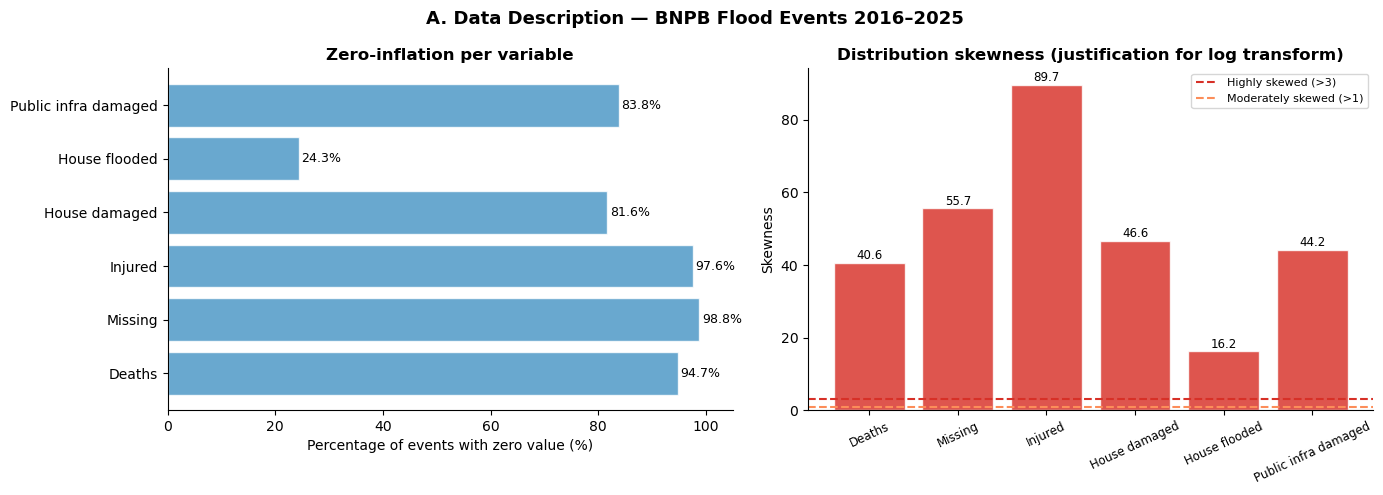

In [5]:
# ══════════════════════════════════════════════════════
# STEP 2 — Summary statistics and data-quality overview
# ══════════════════════════════════════════════════════

stats_df = df[NUM_COLS].describe().T.round(2)
stats_df.columns = ['count','mean','std','min','Q1','median','Q3','max']
stats_df['zero%'] = [(df[c]==0).mean()*100 for c in NUM_COLS]
stats_df['skewness'] = [df[c].skew() for c in NUM_COLS]

LABEL_MAP = {'Meninggal':'Deaths','Hilang':'Missing','Terluka':'Injured',
             'Rumah Rusak':'House damaged','Rumah Terendam':'House flooded',
             'Fasum Rusak':'Public infra damaged'}
stats_df.index = [LABEL_MAP[c] for c in NUM_COLS]

print(f'Dataset: {len(df):,} flood events  |  {df["bps_kab_code"].nunique()} regencies'
      f'  |  38 provinces  |  2016–2025\n')
print(stats_df[['count','mean','median','max','zero%','skewness']]
      .rename(columns={'zero%':'zero (%)','skewness':'skew'}).to_string())

# ── A2. Data quality bar chart ────────────────────────────────────────────
plt.ioff()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('A. Data Description — BNPB Flood Events 2016–2025', fontsize=13, fontweight='bold')

# Zero proportion per variable
ax = axes[0]
labels = list(LABEL_MAP.values())
zero_pct = [(df[c]==0).mean()*100 for c in NUM_COLS]
bars = ax.barh(labels, zero_pct, color='#4393c3', alpha=0.80, edgecolor='white')
for bar, v in zip(bars, zero_pct):
    ax.text(v+0.5, bar.get_y()+bar.get_height()/2, f'{v:.1f}%',
            va='center', fontsize=9)
ax.set_xlabel('Percentage of events with zero value (%)')
ax.set_title('Zero-inflation per variable', fontweight='bold')
ax.set_xlim(0, 105)

# Skewness bar chart
ax2 = axes[1]
skews = [df[c].skew() for c in NUM_COLS]
colors = ['#d73027' if s > 3 else '#fc8d59' if s > 1 else '#4575b4' for s in skews]
bars2 = ax2.bar(labels, skews, color=colors, alpha=0.82, edgecolor='white')
ax2.axhline(3, color='#d73027', lw=1.5, ls='--', label='Highly skewed (>3)')
ax2.axhline(1, color='#fc8d59', lw=1.5, ls='--', label='Moderately skewed (>1)')
for bar, v in zip(bars2, skews):
    ax2.text(bar.get_x()+bar.get_width()/2, v+0.2, f'{v:.1f}',
             ha='center', va='bottom', fontsize=8.5)
ax2.set_ylabel('Skewness')
ax2.set_title('Distribution skewness (justification for log transform)', fontweight='bold')
ax2.tick_params(axis='x', rotation=25, labelsize=8.5)
ax2.legend(fontsize=8)

plt.tight_layout(); plt.ion(); plt.show()


## STEP 3 — Regency-level descriptive statistics (7 variables)

Descriptive statistics for the seven variables at the regency level (cumulative 2016–2025), the same structure used as input to the k-means clustering in Notebooks 5–6.

In [7]:
# ═══════════════════════════════════════════════════════════════════════
# STEP 3 — Regency-level descriptive statistics (7 variables)
# ═══════════════════════════════════════════════════════════════════════
print(f"  A2.1. Regency-level descriptive statistics (n={len(df_regency)} regencies)\n")

# Descriptive stats for 7 variables at regency level
stats_reg = df_regency[NUM_COLS_REGENCY].describe().T.round(2)
stats_reg['zero%'] = [(df_regency[c]==0).mean()*100 for c in NUM_COLS_REGENCY]
stats_reg['skewness'] = [df_regency[c].skew() for c in NUM_COLS_REGENCY]
stats_reg.index = [LABEL_MAP_REGENCY[c] for c in NUM_COLS_REGENCY]
print(stats_reg.to_string())

# Methodology note: comparison with event-level
print(f"""

  INTERPRETATION:
    Each regency now has ONE row aggregating all flood events 2016-2025.
    These are the SAME 7 variables used in nb5/nb6 K-means UNIT A (n=514).
    
    Zero%:
      - event_count zero%: regencies that NEVER flooded (10 years)
      - Other vars zero%: regencies that flooded but had zero specific impact
        (e.g., flooded but no deaths recorded)
    
    Skewness:
      - All 7 variables are RIGHT-SKEWED (high positive)
      - Power-law / heavy-tail distribution typical of disaster data
      - Justifies log1p transformation (applied in nb5/nb6 K-means)
""")

  A2.1. Regency-level descriptive statistics (n=502 regencies)

                         count      mean       std  min    25%     50%       75%       max      zero%   skewness
Flood frequency          502.0     25.96     26.26  1.0    9.0    20.0     34.00     277.0   0.000000   3.237876
Deaths                   502.0      6.06     19.49  0.0    0.0     1.0      4.00     240.0  37.848606   7.940770
Missing                  502.0      1.11      5.02  0.0    0.0     0.0      0.00      82.0  75.099602  10.678745
Injured                  502.0     51.94    507.15  0.0    0.0     0.0      2.00   10382.0  61.952191  17.625590
Houses flooded           502.0  16290.77  33275.48  0.0  656.5  4133.0  16128.25  327593.0   2.191235   4.395328
Houses damaged           502.0    869.54   3410.94  0.0    5.0    53.0    336.75   47208.0  15.537849   8.826178
Public facility damaged  502.0     52.33    157.61  0.0    1.0     8.5     36.00    2037.0  21.513944   7.384861


  INTERPRETATION:
    Each reg

## STEP 4 — Per-variable distribution diagnostics

Per-variable distribution diagnostics for the seven regency-level variables.

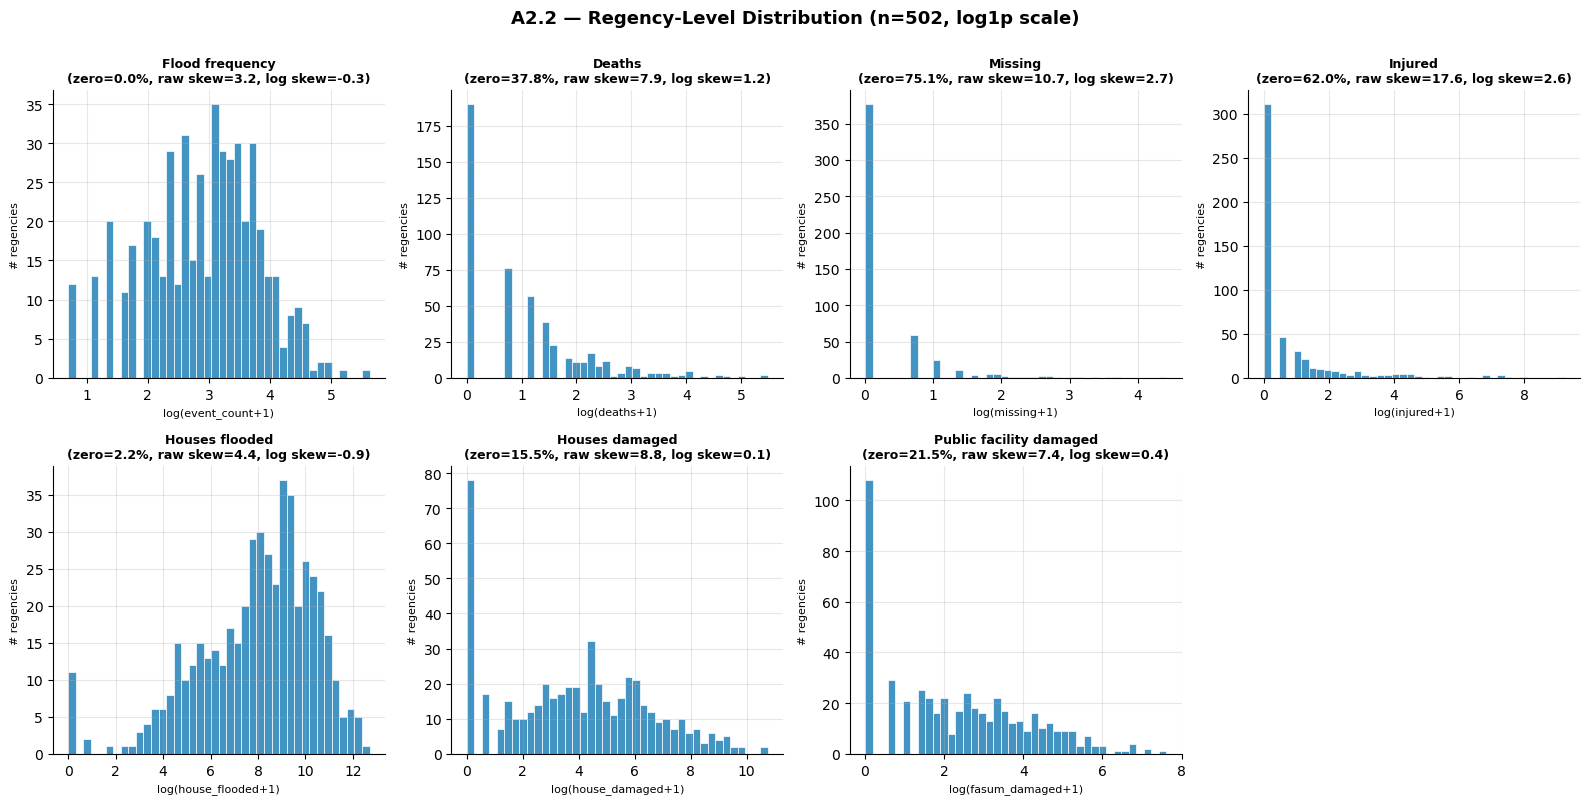


  KEY OBSERVATION FROM DISTRIBUTIONS:
    Log transformation (log1p) significantly reduces skewness across all 7 vars.
    This validates the log1p uniform transformation used in nb5/nb6 K-means.
    
    Variables with high zero%:
      - missing, injured: many regencies flood without specific victim categories
      - event_count: few regencies (~2%) never flood
    
    house_flooded has highest magnitude scale (max often 10^5+):
      - Confirms why z-score may help K-means balance contribution
      - Supports decision to use A2 (log-only) vs A4 (z-scored) trade-off



In [9]:
# ═══════════════════════════════════════════════════════════════════════
# STEP 4 — Per-variable distribution diagnostics
# ═══════════════════════════════════════════════════════════════════════
import math

n_vars = len(NUM_COLS_REGENCY)
ncols = 4
nrows = math.ceil(n_vars / ncols)

plt.ioff()
fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows*4))
axes = axes.flatten()

fig.suptitle(f'A2.2 — Regency-Level Distribution (n={len(df_regency)}, log1p scale)',
             fontsize=13, fontweight='bold', y=1.00)

for i, var in enumerate(NUM_COLS_REGENCY):
    ax = axes[i]
    log_vals = np.log1p(df_regency[var])
    raw_skew = df_regency[var].skew()
    log_skew = log_vals.skew()
    n_zero = (df_regency[var] == 0).sum()
    pct_zero = n_zero / len(df_regency) * 100
    
    ax.hist(log_vals, bins=40, color='#4393c3', edgecolor='white', linewidth=0.5)
    ax.set_title(f"{LABEL_MAP_REGENCY[var]}\n(zero={pct_zero:.1f}%, raw skew={raw_skew:.1f}, log skew={log_skew:.1f})",
                  fontsize=9, fontweight='bold')
    ax.set_xlabel(f'log({var}+1)', fontsize=8)
    ax.set_ylabel('# regencies', fontsize=8)
    ax.grid(True, alpha=0.3)

# Hide unused axes
for j in range(n_vars, len(axes)):
    axes[j].set_visible(False)

plt.tight_layout()
plt.ion()
plt.show()

print(f"""
  KEY OBSERVATION FROM DISTRIBUTIONS:
    Log transformation (log1p) significantly reduces skewness across all 7 vars.
    This validates the log1p uniform transformation used in nb5/nb6 K-means.
    
    Variables with high zero%:
      - missing, injured: many regencies flood without specific victim categories
      - event_count: few regencies (~2%) never flood
    
    house_flooded has highest magnitude scale (max often 10^5+):
      - Confirms why z-score may help K-means balance contribution
      - Supports decision to use A2 (log-only) vs A4 (z-scored) trade-off
""")

## STEP 5 — Annual event counts and key impact trends

Annual event counts and cumulative trends for the key impact variables.

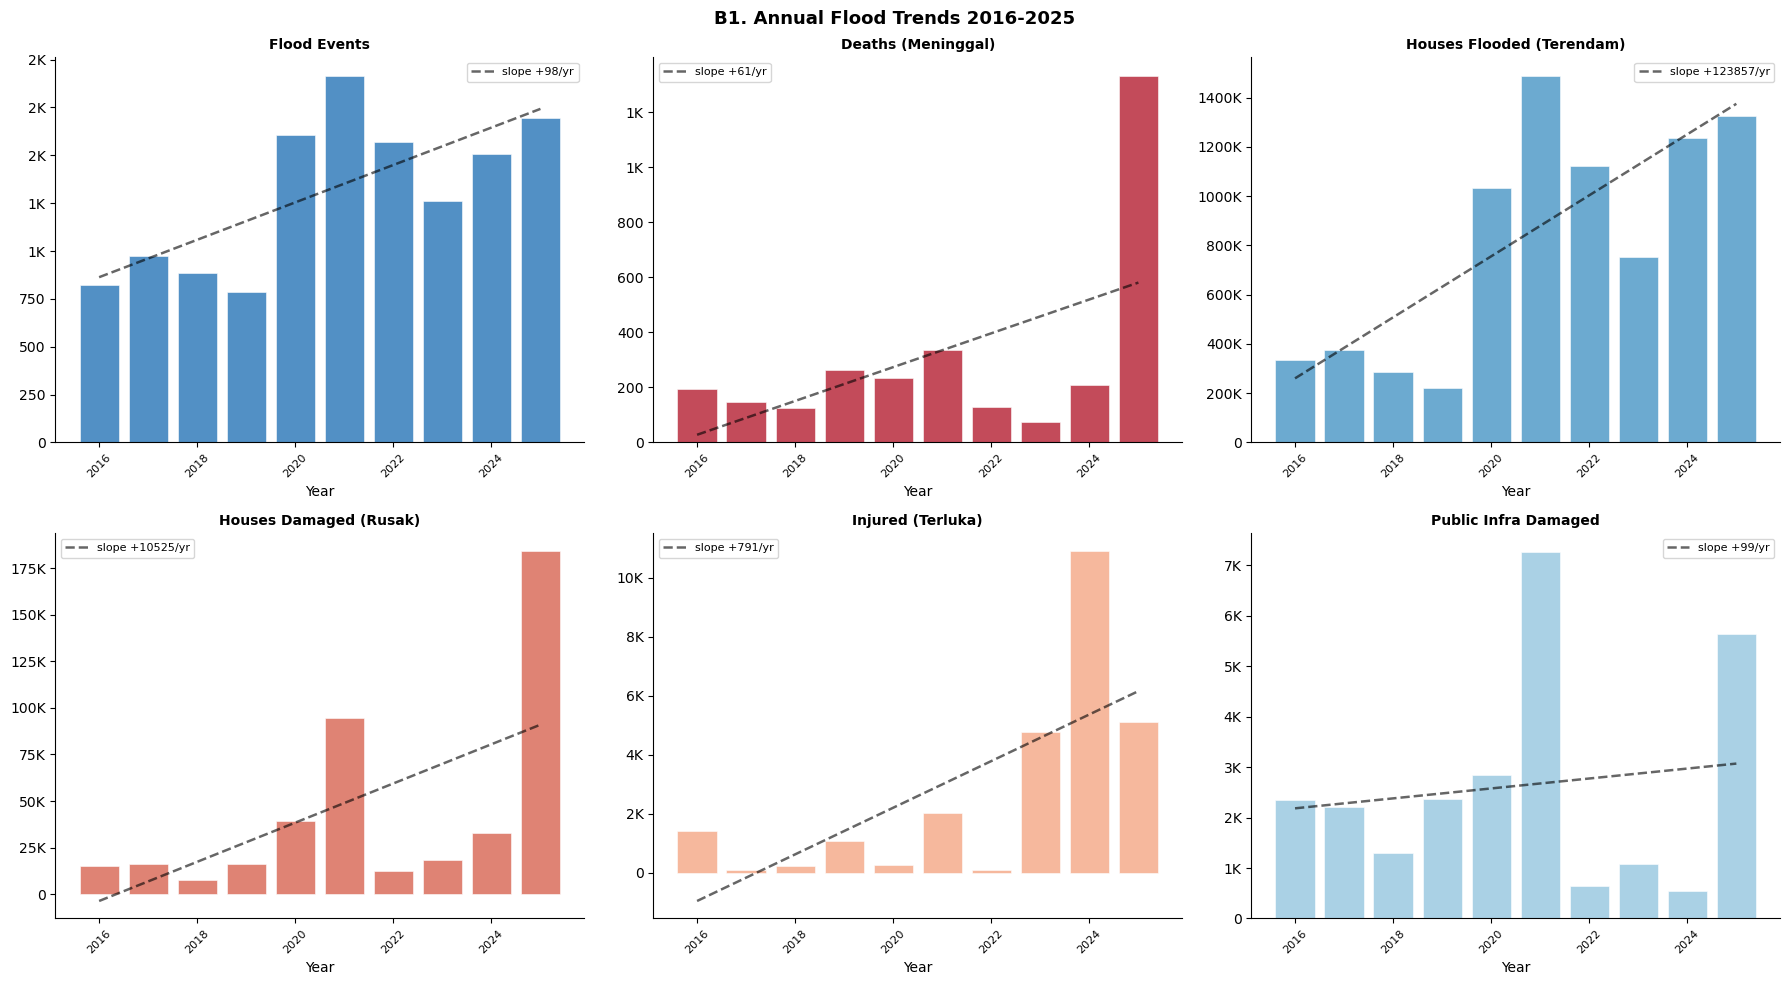

In [11]:
# ══════════════════════════════════════════════════════
# STEP 5 — Annual event counts and key impact trends
# ══════════════════════════════════════════════════════

annual = df.groupby('year').agg(
    events        = ('Kejadian','count'),
    deaths        = ('Meninggal','sum'),
    missing       = ('Hilang','sum'),
    injured       = ('Terluka','sum'),
    house_damaged = ('Rumah Rusak','sum'),
    house_flooded = ('Rumah Terendam','sum'),
    fasum         = ('Fasum Rusak','sum'),
).reset_index()

plt.ioff()
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('B1. Annual Flood Trends 2016-2025', fontsize=13, fontweight='bold')

plot_cfgs = [
    ('events',       'Flood Events',               '#2171b5'),
    ('deaths',       'Deaths (Meninggal)',          '#b2182b'),
    ('house_flooded','Houses Flooded (Terendam)',   '#4393c3'),
    ('house_damaged','Houses Damaged (Rusak)',      '#d6604d'),
    ('injured',      'Injured (Terluka)',            '#f4a582'),
    ('fasum',        'Public Infra Damaged',        '#92c5de'),
]
for ax, (col, label, color) in zip(axes.flat, plot_cfgs):
    ax.bar(annual['year'], annual[col], color=color, alpha=0.78,
           edgecolor='white', linewidth=0.5)
    z = np.polyfit(range(len(YEARS)), annual[col], 1)
    ax.plot(annual['year'], np.poly1d(z)(range(len(YEARS))),
            'k--', lw=1.8, alpha=0.6, label=f'slope {z[0]:+.0f}/yr')
    ax.set_title(label, fontsize=10, fontweight='bold')
    ax.set_xlabel('Year'); ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(
        lambda x,_: f'{x/1000:.0f}K' if x>=1000 else f'{x:.0f}'))
    ax.legend(fontsize=8)
plt.tight_layout(); plt.ion(); plt.show()


## STEP 6 — Monthly seasonality

Monthly seasonality of flood events, with wet- and dry-season context.

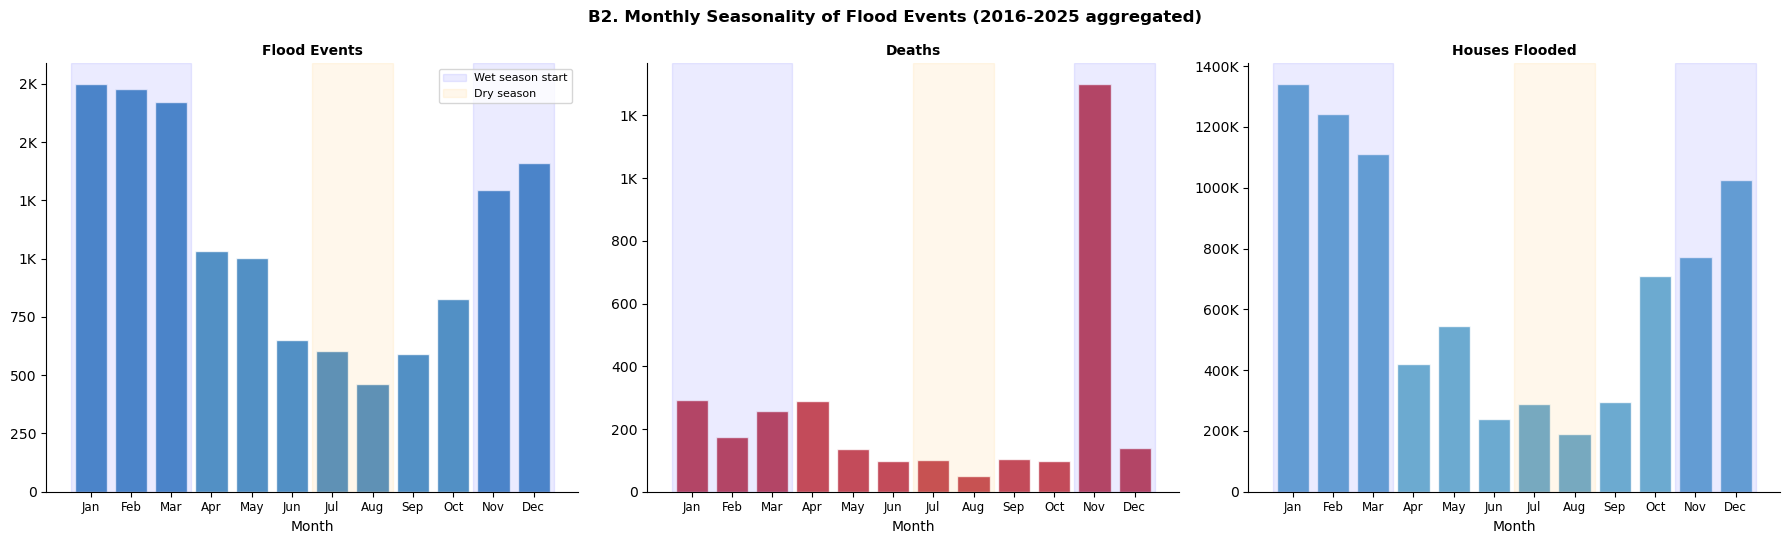

In [13]:
# ══════════════════════════════════════════════════════
# STEP 6 — Monthly seasonality
# ══════════════════════════════════════════════════════

monthly = df.groupby('month').agg(
    events        = ('Kejadian','count'),
    deaths        = ('Meninggal','sum'),
    house_flooded = ('Rumah Terendam','sum'),
).reset_index()

plt.ioff()
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
fig.suptitle('B2. Monthly Seasonality of Flood Events (2016-2025 aggregated)',
             fontsize=12, fontweight='bold')

for ax, (col, label, color) in zip(axes, [
    ('events',       'Flood Events',         '#2171b5'),
    ('deaths',       'Deaths',               '#b2182b'),
    ('house_flooded','Houses Flooded',       '#4393c3'),
]):
    ax.bar(monthly['month'], monthly[col], color=color, alpha=0.78, edgecolor='white')
    ax.set_xticks(range(1,13)); ax.set_xticklabels(MONTHS, fontsize=8.5)
    ax.set_xlabel('Month'); ax.set_title(label, fontsize=10, fontweight='bold')
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(
        lambda x,_: f'{x/1000:.0f}K' if x>=1000 else f'{x:.0f}'))
    # Wet/dry season shading
    ax.axvspan(10.5,12.5, alpha=0.08, color='blue', label='Wet season start')
    ax.axvspan(0.5, 3.5,  alpha=0.08, color='blue')
    ax.axvspan(6.5, 8.5,  alpha=0.08, color='orange', label='Dry season')
    if ax == axes[0]: ax.legend(fontsize=8)
plt.tight_layout(); plt.ion(); plt.show()


## STEP 7 — Year-by-month heatmap

Year-by-month heatmap of event counts.

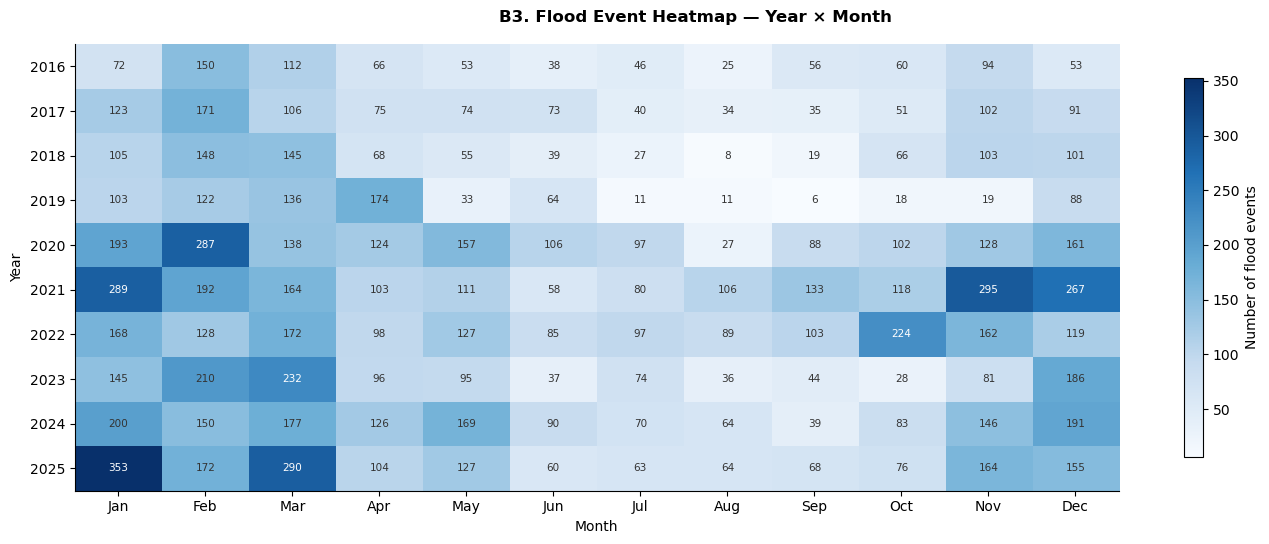

In [15]:
# ══════════════════════════════════════════════════════
# STEP 7 — Year-by-month heatmap
# ══════════════════════════════════════════════════════

pivot = df.groupby(['year','month'])['Kejadian'].count().reset_index()
pivot = pivot.pivot(index='year', columns='month', values='Kejadian').fillna(0)

plt.ioff()
fig, ax = plt.subplots(figsize=(14, 5.5))
fig.suptitle('B3. Flood Event Heatmap — Year × Month', fontsize=12, fontweight='bold')

cmap_h = LinearSegmentedColormap.from_list('flood_heat',
    ['#f7fbff','#c6dbef','#6baed6','#2171b5','#08306b'])
im = ax.imshow(pivot.values, cmap=cmap_h, aspect='auto')
ax.set_xticks(range(12)); ax.set_xticklabels(MONTHS)
ax.set_yticks(range(len(YEARS))); ax.set_yticklabels(YEARS)
ax.set_xlabel('Month'); ax.set_ylabel('Year')
fig.colorbar(im, ax=ax, label='Number of flood events', shrink=0.85)
# Add value annotations
for i, year in enumerate(pivot.index):
    for j, month in enumerate(pivot.columns):
        v = int(pivot.iloc[i,j])
        if v > 0:
            ax.text(j, i, str(v), ha='center', va='center',
                    fontsize=7.5,
                    color='white' if v > pivot.values.max()*0.6 else '#333')
plt.tight_layout(); plt.ion(); plt.show()


## STEP 8 — Events by island over time

Flood events by island group over time.

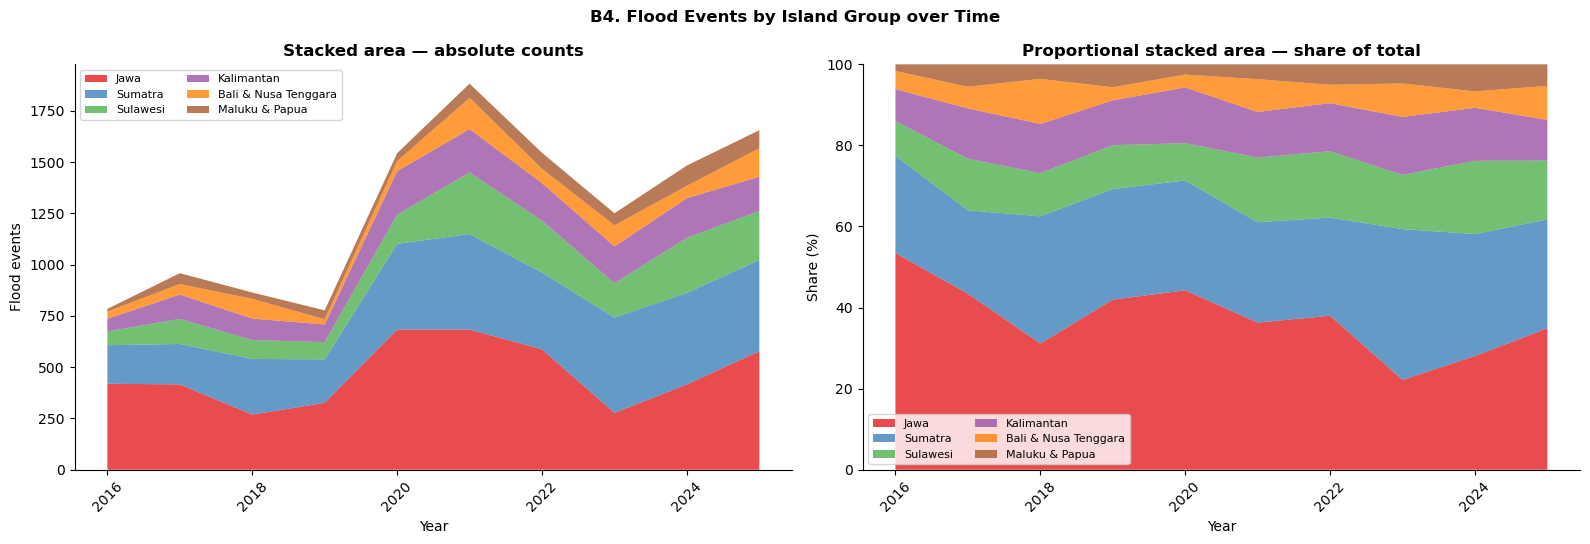

In [17]:
# ══════════════════════════════════════════════════════
# STEP 8 — Events by island over time
# ══════════════════════════════════════════════════════

island_yr = (df[df['island'].isin(ISLAND_ORDER)]
             .groupby(['year','island'])['Kejadian'].count()
             .reset_index().pivot(index='year', columns='island',
                                   values='Kejadian').fillna(0)
             .reindex(columns=ISLAND_ORDER))

plt.ioff()
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
fig.suptitle('B4. Flood Events by Island Group over Time',
             fontsize=12, fontweight='bold')

# Stacked area
axes[0].stackplot(island_yr.index, island_yr.T.values,
                  labels=ISLAND_ORDER, colors=ISLAND_COLORS, alpha=0.78)
axes[0].set_xlabel('Year'); axes[0].set_ylabel('Flood events')
axes[0].set_title('Stacked area — absolute counts', fontweight='bold')
axes[0].legend(loc='upper left', fontsize=8, ncol=2)
axes[0].tick_params(axis='x', rotation=45)

# Proportional stacked area
prop = island_yr.div(island_yr.sum(axis=1), axis=0) * 100
axes[1].stackplot(prop.index, prop.T.values,
                  labels=ISLAND_ORDER, colors=ISLAND_COLORS, alpha=0.78)
axes[1].set_xlabel('Year'); axes[1].set_ylabel('Share (%)')
axes[1].set_title('Proportional stacked area — share of total', fontweight='bold')
axes[1].legend(loc='lower left', fontsize=8, ncol=2)
axes[1].tick_params(axis='x', rotation=45)
axes[1].set_ylim(0, 100)

plt.tight_layout(); plt.ion(); plt.show()


## STEP 9 — Top provinces by events, deaths, and houses flooded

Provinces ranked by events, deaths, and houses flooded.

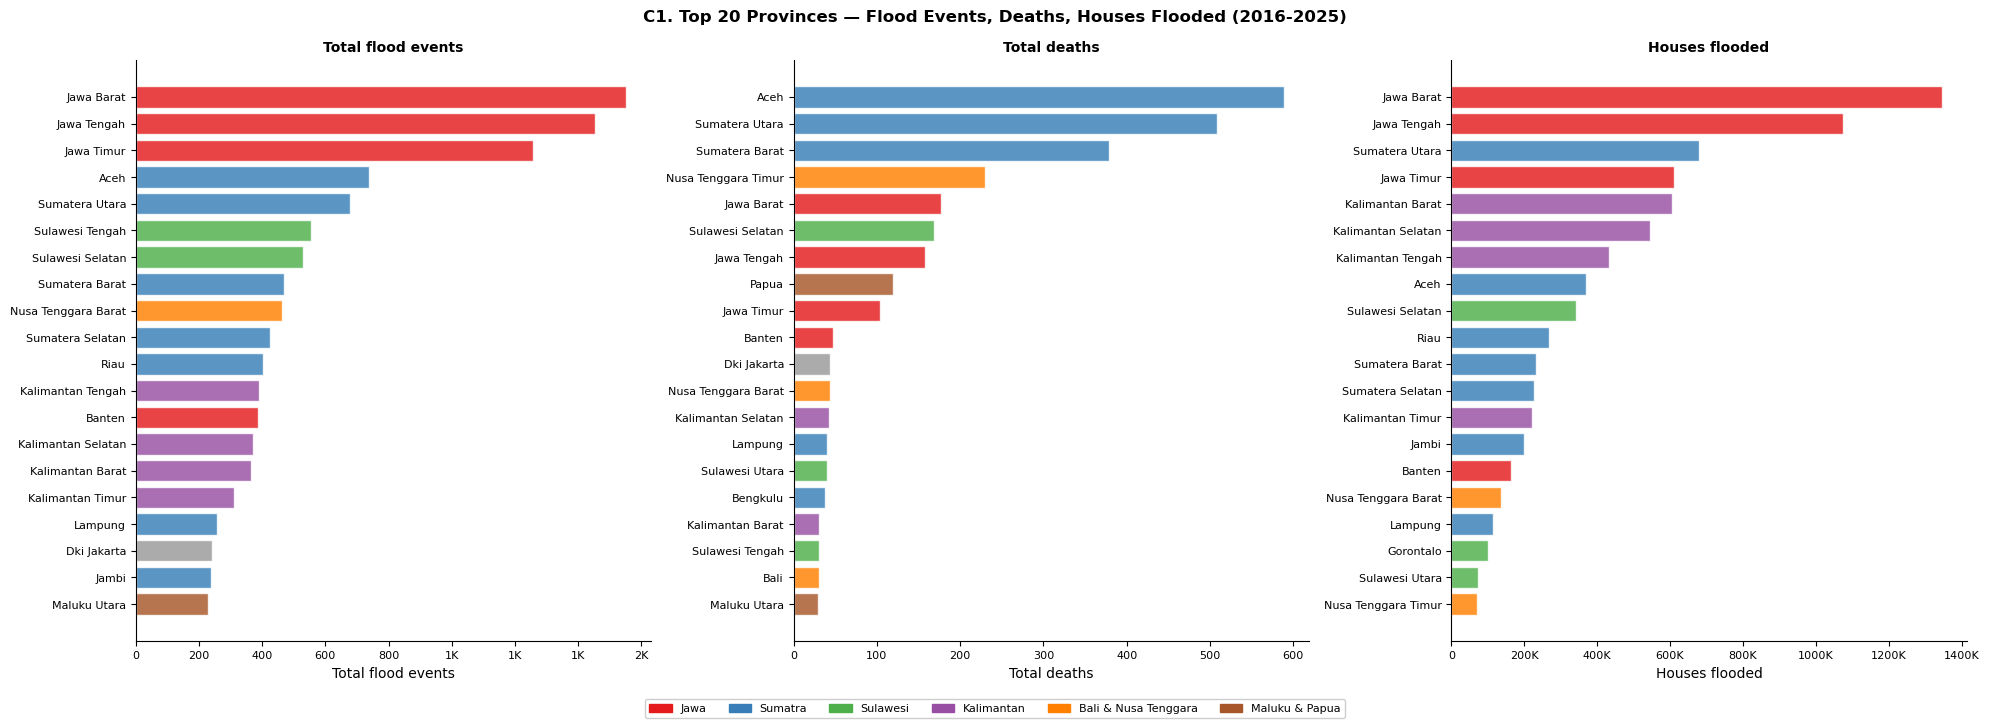

In [19]:
# ══════════════════════════════════════════════════════
# STEP 9 — Top provinces by events, deaths, and houses flooded
# ══════════════════════════════════════════════════════

prov = df.groupby('bps_prov_name').agg(
    events        = ('Kejadian','count'),
    deaths        = ('Meninggal','sum'),
    house_flooded = ('Rumah Terendam','sum'),
).reset_index().rename(columns={'bps_prov_name':'province'})
prov['island'] = prov['province'].map(ISLAND_MAP).fillna('Other')
TOP = 20

plt.ioff()
fig, axes = plt.subplots(1, 3, figsize=(20, 7))
fig.suptitle(f'C1. Top {TOP} Provinces — Flood Events, Deaths, Houses Flooded (2016-2025)',
             fontsize=12, fontweight='bold')

for ax, (col, label, cmap_name) in zip(axes, [
    ('events',       'Total flood events',    'Blues'),
    ('deaths',       'Total deaths',          'Reds'),
    ('house_flooded','Houses flooded',        'Blues'),
]):
    top_p = prov.nlargest(TOP, col)
    colors_p = [ISLAND_COLORS[ISLAND_ORDER.index(i)]
                if i in ISLAND_ORDER else '#999'
                for i in top_p['island']]
    bars = ax.barh(top_p['province'], top_p[col],
                   color=colors_p, alpha=0.82, edgecolor='white')
    ax.set_xlabel(label); ax.invert_yaxis()
    ax.set_title(label, fontweight='bold', fontsize=10)
    ax.tick_params(labelsize=8)
    ax.xaxis.set_major_formatter(mticker.FuncFormatter(
        lambda x,_: f'{x/1000:.0f}K' if x>=1000 else f'{x:.0f}'))

# Island color legend
handles = [mpatches.Patch(color=c, label=l)
           for l,c in zip(ISLAND_ORDER, ISLAND_COLORS)]
fig.legend(handles=handles, loc='lower center', ncol=6, fontsize=8,
           bbox_to_anchor=(0.5,-0.04), framealpha=0.95)
plt.tight_layout(); plt.ion(); plt.show()


## STEP 10 — Island comparison

Comparison of flood burden across island groups.

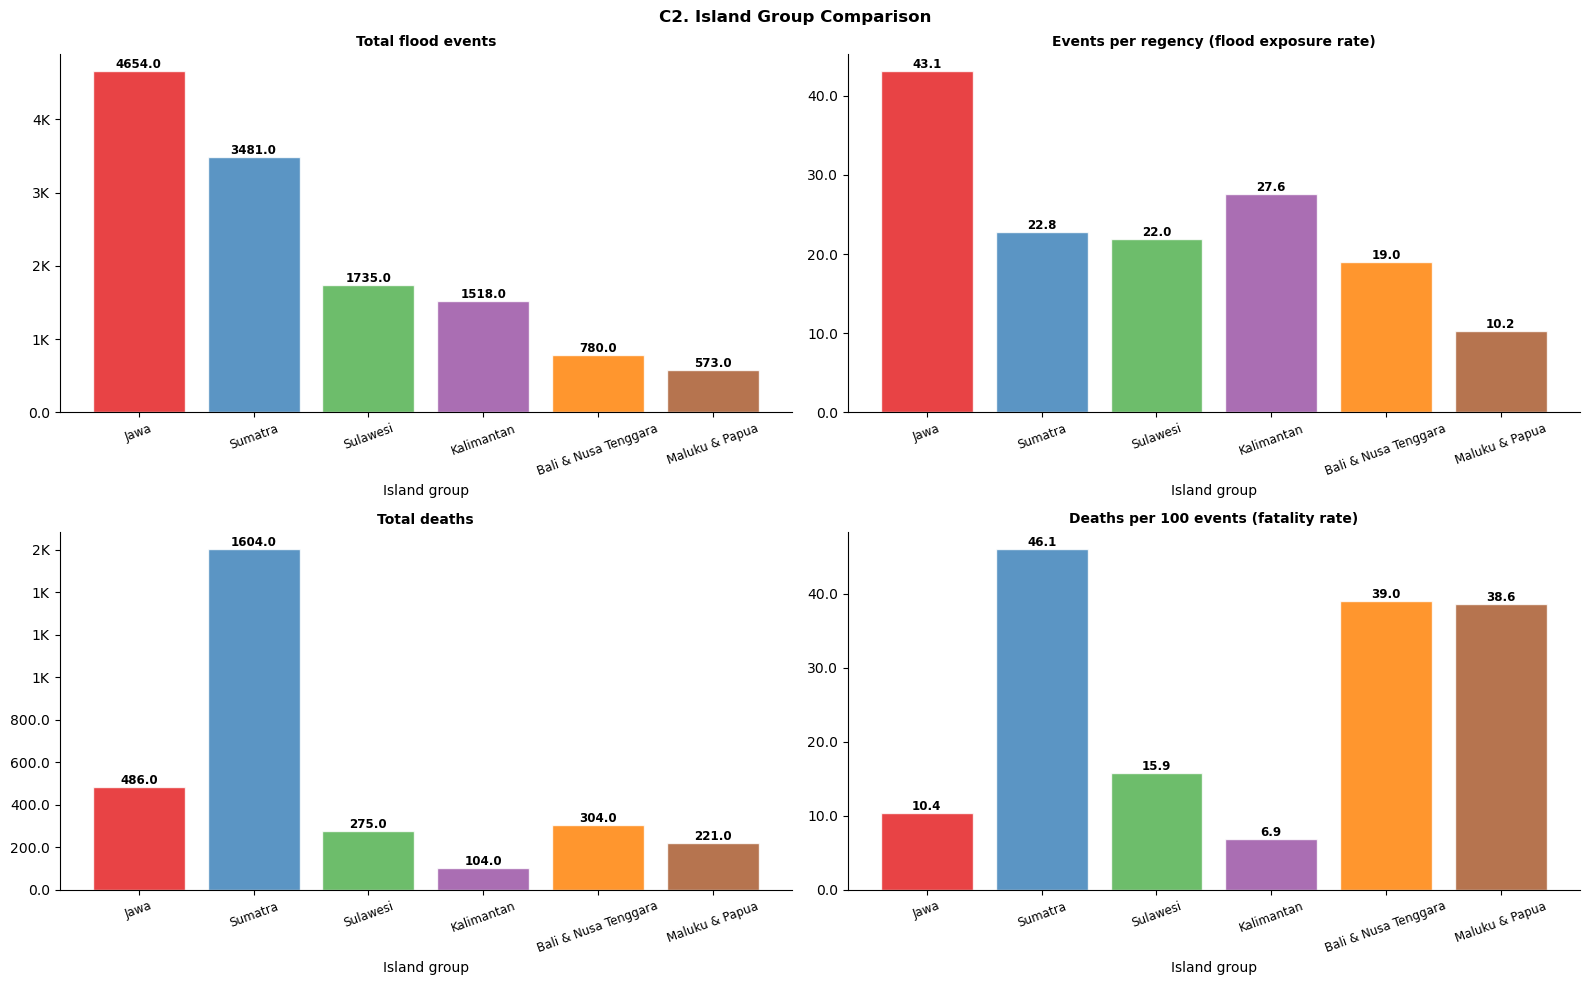

In [21]:
# ══════════════════════════════════════════════════════
# STEP 10 — Island comparison
# ══════════════════════════════════════════════════════

isl = (df[df['island'].isin(ISLAND_ORDER)]
       .groupby('island').agg(
           events        = ('Kejadian','count'),
           deaths        = ('Meninggal','sum'),
           house_flooded = ('Rumah Terendam','sum'),
           regencies     = ('bps_kab_code','nunique'),
       ).reindex(ISLAND_ORDER).reset_index())
isl['events_per_reg'] = isl['events'] / isl['regencies']
isl['deaths_per_event'] = isl['deaths'] / isl['events'] * 100

plt.ioff()
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('C2. Island Group Comparison', fontsize=12, fontweight='bold')

for ax, (col, label, norm_col, norm_label) in zip(axes.flat, [
    ('events','Total flood events',None,None),
    ('events_per_reg','Events per regency (flood exposure rate)',None,None),
    ('deaths','Total deaths',None,None),
    ('deaths_per_event','Deaths per 100 events (fatality rate)',None,None),
]):
    vals = isl[col]
    bars = ax.bar(isl['island'], vals, color=ISLAND_COLORS, alpha=0.82, edgecolor='white')
    for bar, v in zip(bars, vals):
        ax.text(bar.get_x()+bar.get_width()/2, v, f'{v:.1f}',
                ha='center', va='bottom', fontsize=8.5, fontweight='bold')
    ax.set_xlabel('Island group')
    ax.set_title(label, fontweight='bold', fontsize=10)
    ax.tick_params(axis='x', rotation=20, labelsize=8.5)
    ax.yaxis.set_major_formatter(mticker.FuncFormatter(
        lambda x,_: f'{x/1000:.0f}K' if x>=1000 else f'{x:.1f}'))
plt.tight_layout(); plt.ion(); plt.show()


## STEP 11 — Raw versus log-transformed distributions

Raw versus log-transformed distributions of the impact variables.

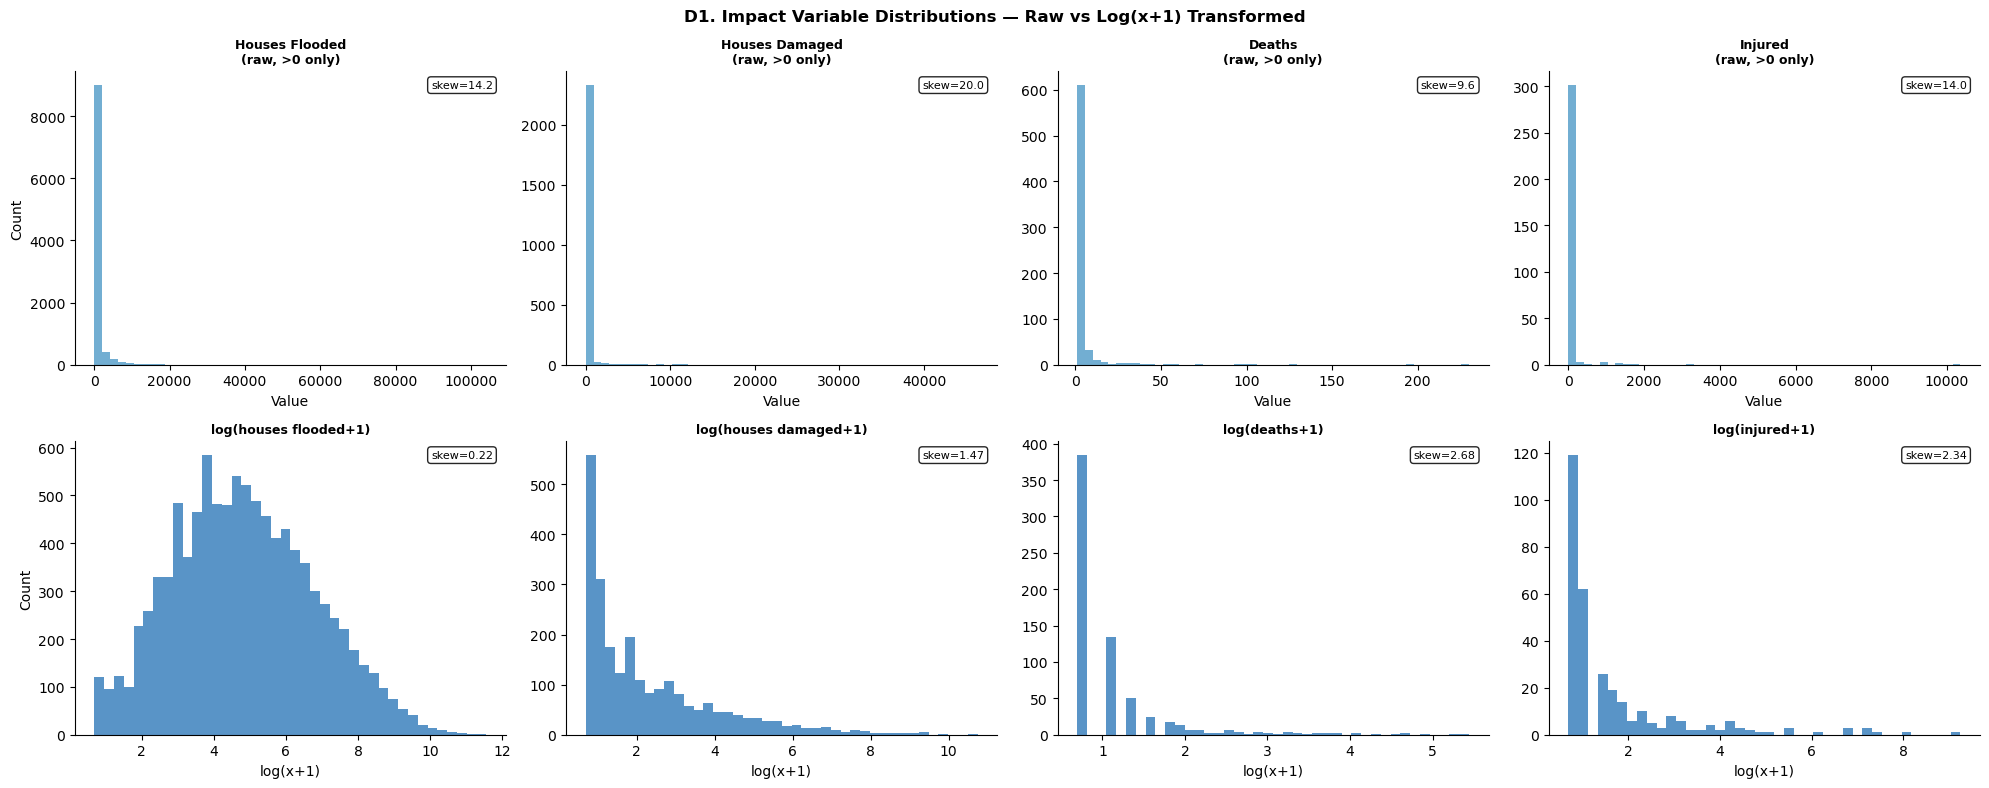

In [23]:
# ══════════════════════════════════════════════════════
# STEP 11 — Raw versus log-transformed distributions
# ══════════════════════════════════════════════════════

PLOT_VARS = ['Rumah Terendam','Rumah Rusak','Meninggal','Terluka']
PLOT_LABELS = ['Houses Flooded','Houses Damaged','Deaths','Injured']

plt.ioff()
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
fig.suptitle('D1. Impact Variable Distributions — Raw vs Log(x+1) Transformed',
             fontsize=12, fontweight='bold')

for i, (col, label) in enumerate(zip(PLOT_VARS, PLOT_LABELS)):
    raw = df[df[col]>0][col]
    log = np.log1p(df[df[col]>0][col])

    # Raw histogram
    ax_r = axes[0, i]
    ax_r.hist(raw, bins=50, color='#4393c3', alpha=0.75, edgecolor='none')
    ax_r.set_title(f'{label}\n(raw, >0 only)', fontsize=9, fontweight='bold')
    ax_r.set_xlabel('Value'); ax_r.set_ylabel('Count' if i==0 else '')
    ax_r.text(0.97,0.97, f'skew={raw.skew():.1f}',
              transform=ax_r.transAxes, ha='right', va='top', fontsize=8,
              bbox=dict(boxstyle='round,pad=0.3',facecolor='white',alpha=0.85))

    # Log histogram
    ax_l = axes[1, i]
    ax_l.hist(log, bins=40, color='#2171b5', alpha=0.75, edgecolor='none')
    ax_l.set_title(f'log({label.lower()}+1)', fontsize=9, fontweight='bold')
    ax_l.set_xlabel('log(x+1)'); ax_l.set_ylabel('Count' if i==0 else '')
    ax_l.text(0.97,0.97, f'skew={log.skew():.2f}',
              transform=ax_l.transAxes, ha='right', va='top', fontsize=8,
              bbox=dict(boxstyle='round,pad=0.3',facecolor='white',alpha=0.85))

plt.tight_layout(); plt.ion(); plt.show()


## STEP 12 — Event severity classification

Classification of each event by the types of impact it caused.

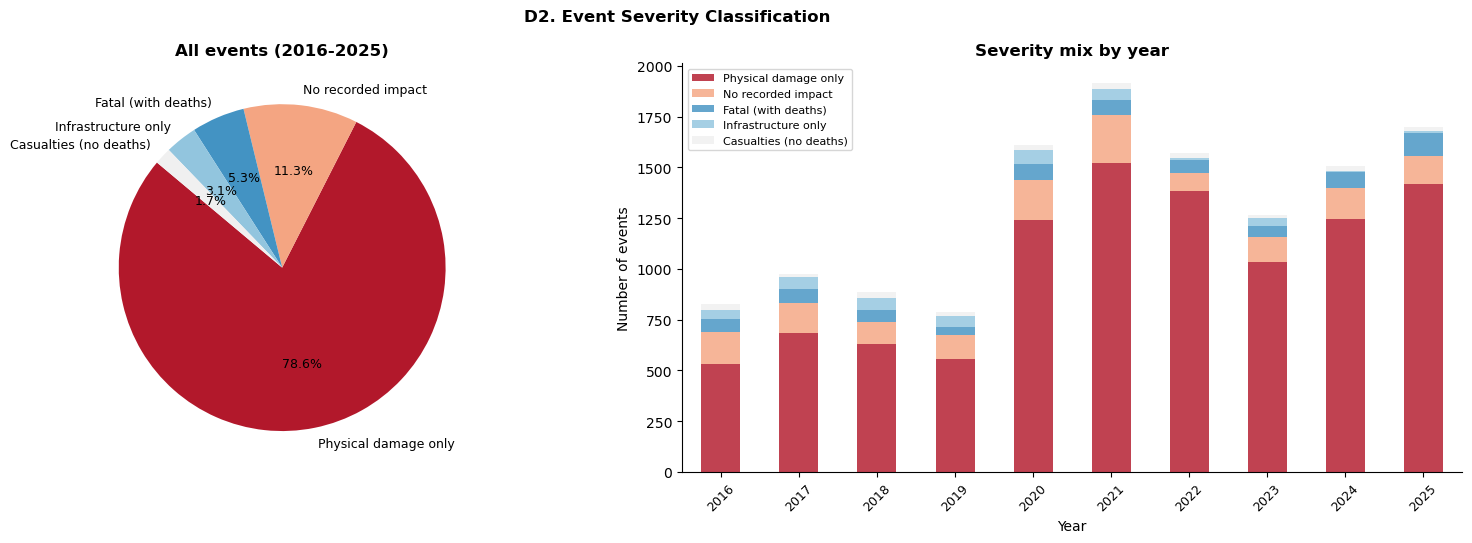

In [25]:
# ══════════════════════════════════════════════════════
# STEP 12 — Event severity classification
# ══════════════════════════════════════════════════════

# Classify each event by the types of impact it had
df['has_death']  = df['Meninggal'] > 0
df['has_injury'] = df['Terluka']   > 0
df['has_missing']= df['Hilang']    > 0
df['has_house']  = (df['Rumah Rusak'] + df['Rumah Terendam']) > 0
df['has_infra']  = df['Fasum Rusak'] > 0
df['n_impact_types'] = (df[['has_death','has_injury','has_missing',
                              'has_house','has_infra']].sum(axis=1))
def classify_severity(row):
    if row['has_death']:   return 'Fatal (with deaths)'
    if row['has_injury'] or row['has_missing']: return 'Casualties (no deaths)'
    if row['has_house']:   return 'Physical damage only'
    if row['has_infra']:   return 'Infrastructure only'
    return 'No recorded impact'
df['severity_class'] = df.apply(classify_severity, axis=1)

plt.ioff()
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
fig.suptitle('D2. Event Severity Classification', fontsize=12, fontweight='bold')

# Pie chart
vc = df['severity_class'].value_counts()
sev_colors = ['#b2182b','#f4a582','#4393c3','#92c5de','#f0f0f0']
axes[0].pie(vc.values, labels=vc.index, autopct='%1.1f%%',
            colors=sev_colors[:len(vc)], startangle=140,
            textprops={'fontsize':9})
axes[0].set_title('All events (2016-2025)', fontweight='bold')

# Stacked bar by year
sev_yr = (df.groupby(['year','severity_class']).size()
          .reset_index(name='count')
          .pivot(index='year',columns='severity_class',values='count')
          .fillna(0).reindex(columns=vc.index))
sev_yr.plot(kind='bar', stacked=True, ax=axes[1],
            color=sev_colors[:len(vc.index)], alpha=0.82,
            edgecolor='none', legend=True)
axes[1].set_xlabel('Year'); axes[1].set_ylabel('Number of events')
axes[1].set_title('Severity mix by year', fontweight='bold')
axes[1].tick_params(axis='x', rotation=45, labelsize=9)
axes[1].legend(fontsize=8, loc='upper left')

plt.tight_layout(); plt.ion(); plt.show()


## STEP 13 — Deadliest events

The deadliest recorded flood events.

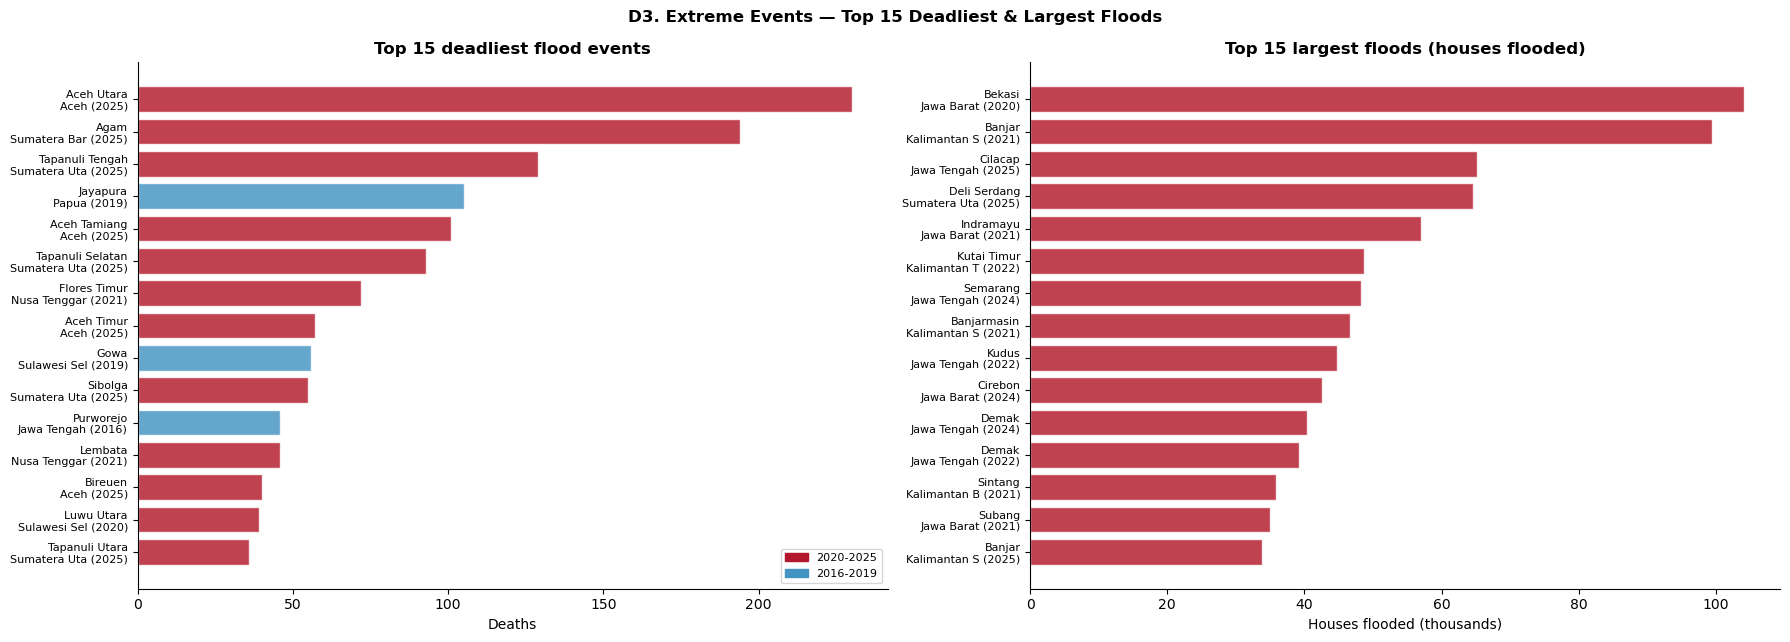

In [27]:
# ══════════════════════════════════════════════════════
# STEP 13 — Deadliest events
# ══════════════════════════════════════════════════════

top15 = df.nlargest(15, 'Meninggal').copy()
top15['label'] = (top15['bps_kab_name'].str.replace('Kab. ','').str.replace('Kota ','')
                  + '\n' + top15['bps_prov_name'].str[:12]
                  + ' (' + top15['year'].astype(str) + ')')

plt.ioff()
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
fig.suptitle('D3. Extreme Events — Top 15 Deadliest & Largest Floods',
             fontsize=12, fontweight='bold')

# Deadliest
ax = axes[0]
colors_d = ['#b2182b' if y >= 2020 else '#4393c3' for y in top15['year']]
ax.barh(range(len(top15)), top15['Meninggal'].values,
        color=colors_d, alpha=0.82, edgecolor='white')
ax.set_yticks(range(len(top15)))
ax.set_yticklabels(top15['label'].values, fontsize=8)
ax.set_xlabel('Deaths'); ax.invert_yaxis()
ax.set_title('Top 15 deadliest flood events', fontweight='bold')
ax.legend(handles=[mpatches.Patch(color='#b2182b',label='2020-2025'),
                   mpatches.Patch(color='#4393c3',label='2016-2019')],
          fontsize=8)

# Largest by houses flooded
top15f = df.nlargest(15,'Rumah Terendam').copy()
top15f['label'] = (top15f['bps_kab_name'].str.replace('Kab. ','').str.replace('Kota ','')
                   + '\n' + top15f['bps_prov_name'].str[:12]
                   + ' (' + top15f['year'].astype(str) + ')')
colors_f=['#b2182b' if y>=2020 else '#4393c3' for y in top15f['year']]
axes[1].barh(range(len(top15f)), top15f['Rumah Terendam'].values/1000,
             color=colors_f, alpha=0.82, edgecolor='white')
axes[1].set_yticks(range(len(top15f)))
axes[1].set_yticklabels(top15f['label'].values, fontsize=8)
axes[1].set_xlabel('Houses flooded (thousands)'); axes[1].invert_yaxis()
axes[1].set_title('Top 15 largest floods (houses flooded)', fontweight='bold')

plt.tight_layout(); plt.ion(); plt.show()


## STEP 14 — Correlation of flood dimensions (log-transformed)

Pairwise correlation of the seven flood dimensions (log-transformed, regency level).

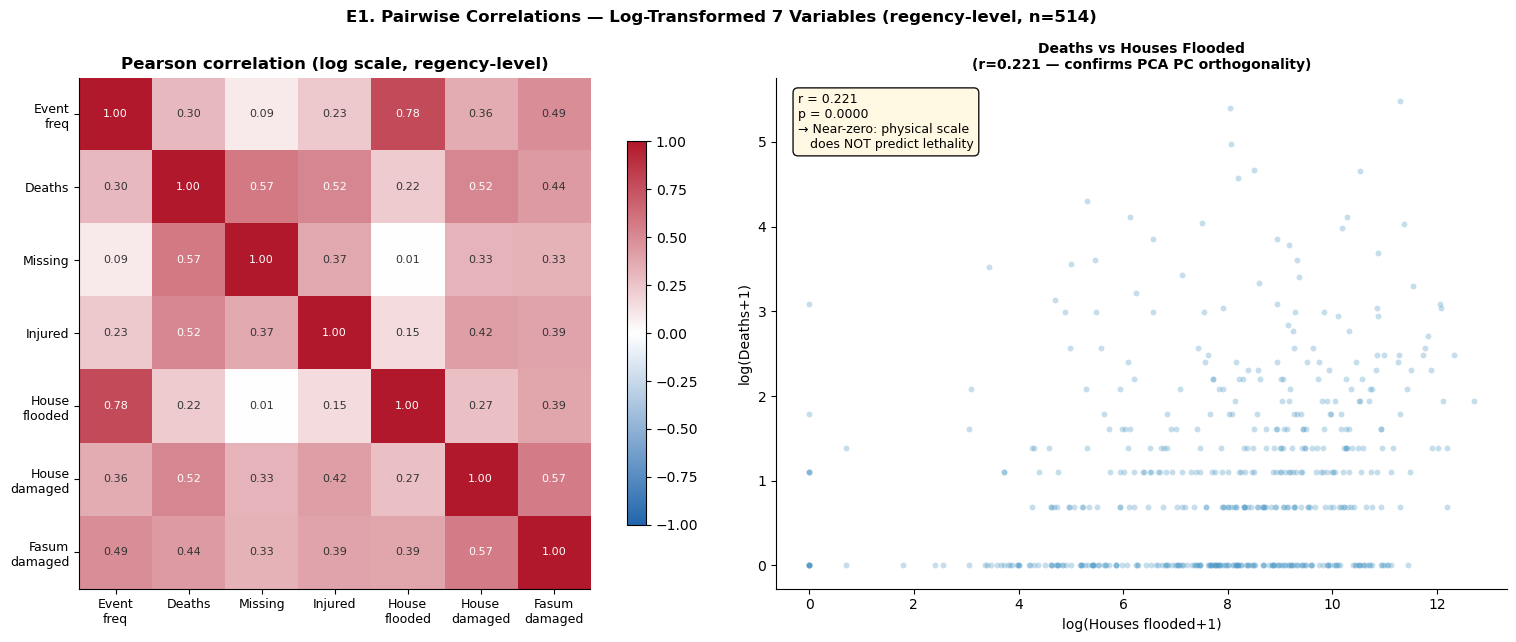

In [29]:
# ══════════════════════════════════════════════════════
# STEP 14 — Correlation of flood dimensions (log-transformed)
# ══════════════════════════════════════════════════════

# REGENCY-LEVEL correlation (n=514, 7 variables aligned with nb5/nb6 K-means)
log_df = df_regency[NUM_COLS_REGENCY].apply(np.log1p)
corr   = log_df.corr()
labels_e = ['Event\nfreq', 'Deaths', 'Missing', 'Injured',
            'House\nflooded', 'House\ndamaged', 'Fasum\ndamaged']
n_vars = len(NUM_COLS_REGENCY)  # 7

plt.ioff()
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
fig.suptitle('E1. Pairwise Correlations — Log-Transformed 7 Variables (regency-level, n=514)',
             fontsize=12, fontweight='bold')

# Heatmap
ax = axes[0]
cmap_c = LinearSegmentedColormap.from_list('corr',['#2166ac','white','#b2182b'])
im = ax.imshow(corr.values, cmap=cmap_c, vmin=-1, vmax=1)
ax.set_xticks(range(n_vars)); ax.set_xticklabels(labels_e, fontsize=9, rotation=0)
ax.set_yticks(range(n_vars)); ax.set_yticklabels(labels_e, fontsize=9)
for i in range(n_vars):
    for j in range(n_vars):
        v = corr.values[i,j]
        ax.text(j, i, f'{v:.2f}', ha='center', va='center', fontsize=8,
                color='white' if abs(v) > 0.5 else '#333')
fig.colorbar(im, ax=ax, shrink=0.75)
ax.set_title('Pearson correlation (log scale, regency-level)', fontweight='bold')

# Key finding: Deaths vs House Flooded correlation (regency-level)
ax2 = axes[1]
ax2.scatter(np.log1p(df_regency['house_flooded']), np.log1p(df_regency['deaths']),
            alpha=0.3, s=18, color='#4393c3', linewidths=0)
ax2.set_xlabel('log(Houses flooded+1)', fontsize=10)
ax2.set_ylabel('log(Deaths+1)', fontsize=10)
r,p = stats.pearsonr(log_df['house_flooded'], log_df['deaths'])
ax2.set_title(f'Deaths vs Houses Flooded\n(r={r:.3f} — confirms PCA PC orthogonality)',
              fontweight='bold', fontsize=10)
ax2.text(0.03,0.97,
         f'r = {r:.3f}\np = {p:.4f}\n→ Near-zero: physical scale\n   does NOT predict lethality',
         transform=ax2.transAxes, fontsize=9, va='top',
         bbox=dict(boxstyle='round,pad=0.4',facecolor='#fff8e1',alpha=0.92))

plt.tight_layout(); plt.ion(); plt.show()


## STEP 15 — Regency-level frequency versus impact

Regency-level relationship between event frequency and impact.

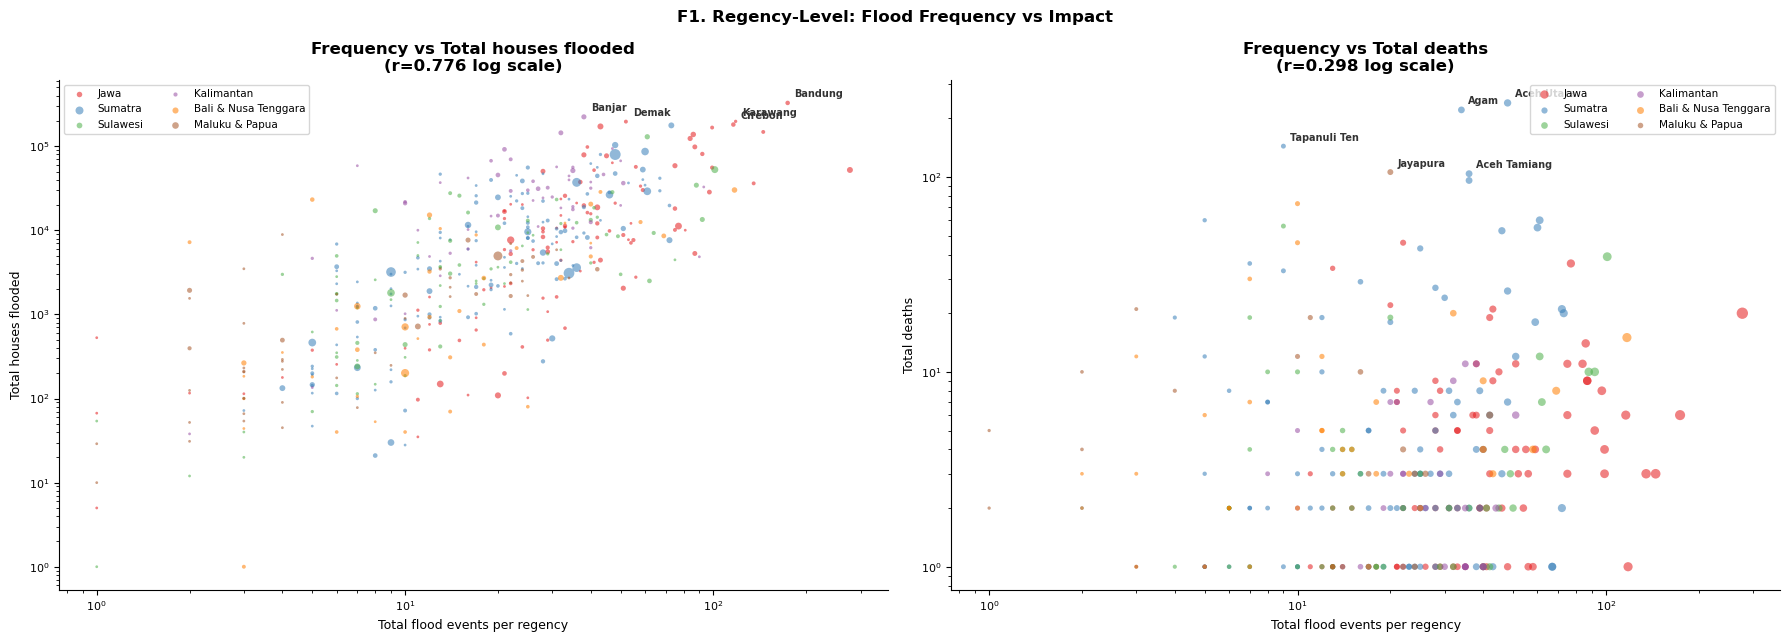

In [31]:
# ══════════════════════════════════════════════════════
# STEP 15 — Regency-level frequency versus impact
# ══════════════════════════════════════════════════════

reg = df.groupby(['bps_kab_code','bps_kab_name','bps_prov_name']).agg(
    events        = ('Kejadian','count'),
    deaths        = ('Meninggal','sum'),
    house_flooded = ('Rumah Terendam','sum'),
    injured       = ('Terluka','sum'),
).reset_index()
reg['island'] = reg['bps_prov_name'].map(ISLAND_MAP).fillna('Other')
reg['deaths_per_event'] = reg['deaths'] / reg['events']

plt.ioff()
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
fig.suptitle('F1. Regency-Level: Flood Frequency vs Impact',
             fontsize=12, fontweight='bold')

for ax, (y_col, y_label, size_col) in zip(axes, [
    ('house_flooded','Total houses flooded','deaths'),
    ('deaths','Total deaths','events'),
]):
    for isl, color in zip(ISLAND_ORDER, ISLAND_COLORS):
        sub = reg[reg['island']==isl]
        size = np.sqrt(sub[size_col]+1) * 4
        ax.scatter(sub['events'], sub[y_col], c=color, s=size,
                   alpha=0.55, label=isl, linewidths=0)
    # Annotate top 5
    for _, row in reg.nlargest(5,y_col).iterrows():
        ax.annotate(row['bps_kab_name'].replace('Kab. ','').replace('Kota ','')[:12],
                    (row['events'],row[y_col]),
                    xytext=(5,4),textcoords='offset points',
                    fontsize=7,color='#333',fontweight='bold')
    r,_ = stats.pearsonr(np.log1p(reg['events']), np.log1p(reg[y_col]))
    ax.set_xlabel('Total flood events per regency', fontsize=9)
    ax.set_ylabel(y_label, fontsize=9)
    ax.set_title(f'Frequency vs {y_label}\n(r={r:.3f} log scale)', fontweight='bold')
    ax.legend(fontsize=7.5, ncol=2)
    ax.set_yscale('log'); ax.set_xscale('log')
    ax.tick_params(labelsize=8)

plt.tight_layout(); plt.ion(); plt.show()


## STEP 16 — Fatality rate versus event frequency

Relationship between fatality rate and event frequency (high frequency does not imply high mortality).

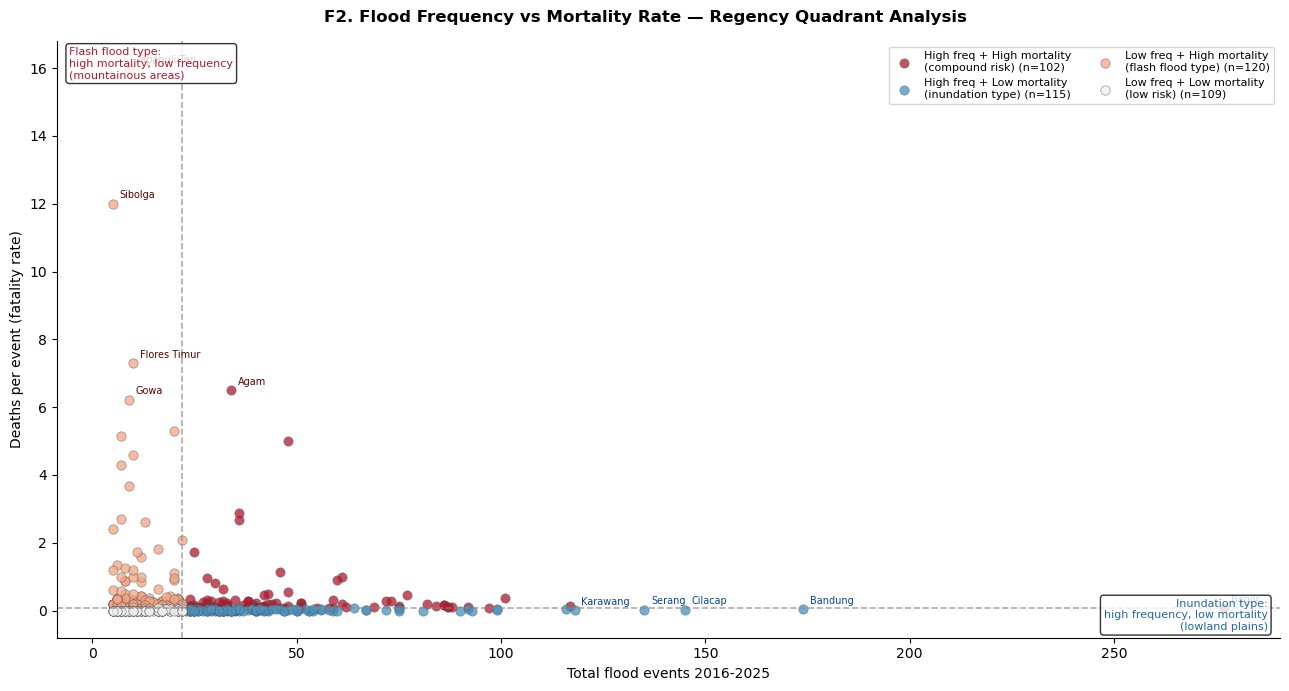

In [33]:
# ══════════════════════════════════════════════════════
# STEP 16 — Fatality rate versus event frequency
# ══════════════════════════════════════════════════════

# Key thesis finding: high frequency ≠ high mortality
# Divergent: regencies with many floods but low deaths (inundation type)
# vs few floods but high mortality (flash flood type)

reg2 = reg[reg['events'] >= 5].copy()  # at least 5 events
reg2['fatality_rate'] = reg2['deaths'] / reg2['events']

# Quadrant classification
freq_med = reg2['events'].median()
death_med = reg2['deaths_per_event'].median()

def quad_class(row):
    hi_freq = row['events'] > freq_med
    hi_death = row['deaths_per_event'] > death_med
    if hi_freq and hi_death:  return 'High freq + High mortality\n(compound risk)'
    if hi_freq and not hi_death: return 'High freq + Low mortality\n(inundation type)'
    if not hi_freq and hi_death: return 'Low freq + High mortality\n(flash flood type)'
    return 'Low freq + Low mortality\n(low risk)'
reg2['quad'] = reg2.apply(quad_class, axis=1)

quad_colors = {
    'High freq + High mortality\n(compound risk)'  : '#b2182b',
    'High freq + Low mortality\n(inundation type)' : '#4393c3',
    'Low freq + High mortality\n(flash flood type)': '#f4a582',
    'Low freq + Low mortality\n(low risk)'         : '#f0f0f0',
}

plt.ioff()
fig, ax = plt.subplots(figsize=(13, 7))
fig.suptitle('F2. Flood Frequency vs Mortality Rate — Regency Quadrant Analysis',
             fontsize=12, fontweight='bold')

for quad, color in quad_colors.items():
    sub = reg2[reg2['quad']==quad]
    ax.scatter(sub['events'], sub['deaths_per_event'],
               c=color, s=45, alpha=0.75, label=f'{quad} (n={len(sub)})',
               linewidths=0.4, edgecolors='#555')

# Quadrant dividers
ax.axvline(freq_med, color='#888', lw=1.2, ls='--', alpha=0.7)
ax.axhline(death_med, color='#888', lw=1.2, ls='--', alpha=0.7)

# Annotate extremes
for _, row in reg2.nlargest(5,'deaths_per_event').iterrows():
    ax.annotate(row['bps_kab_name'].replace('Kab. ','').replace('Kota ','')[:12],
                (row['events'],row['deaths_per_event']),
                xytext=(5,4),textcoords='offset points',fontsize=7,color='#5c0000')
for _, row in reg2.nlargest(5,'events').iterrows():
    ax.annotate(row['bps_kab_name'].replace('Kab. ','').replace('Kota ','')[:12],
                (row['events'],row['deaths_per_event']),
                xytext=(5,4),textcoords='offset points',fontsize=7,color='#084594')

ax.set_xlabel('Total flood events 2016-2025', fontsize=10)
ax.set_ylabel('Deaths per event (fatality rate)', fontsize=10)
ax.legend(fontsize=8, loc='upper right', ncol=2)
ax.text(0.01,0.99,'Flash flood type:\nhigh mortality, low frequency\n(mountainous areas)',
        transform=ax.transAxes,fontsize=8,va='top',color='#b2182b',
        bbox=dict(boxstyle='round',facecolor='white',alpha=0.8))
ax.text(0.99,0.01,'Inundation type:\nhigh frequency, low mortality\n(lowland plains)',
        transform=ax.transAxes,fontsize=8,va='bottom',ha='right',color='#2166ac',
        bbox=dict(boxstyle='round',facecolor='white',alpha=0.8))

plt.tight_layout(); plt.ion(); plt.show()


## STEP 17 — Regency bubble maps by dimension

Centroid bubble maps for each flood dimension across Indonesia.

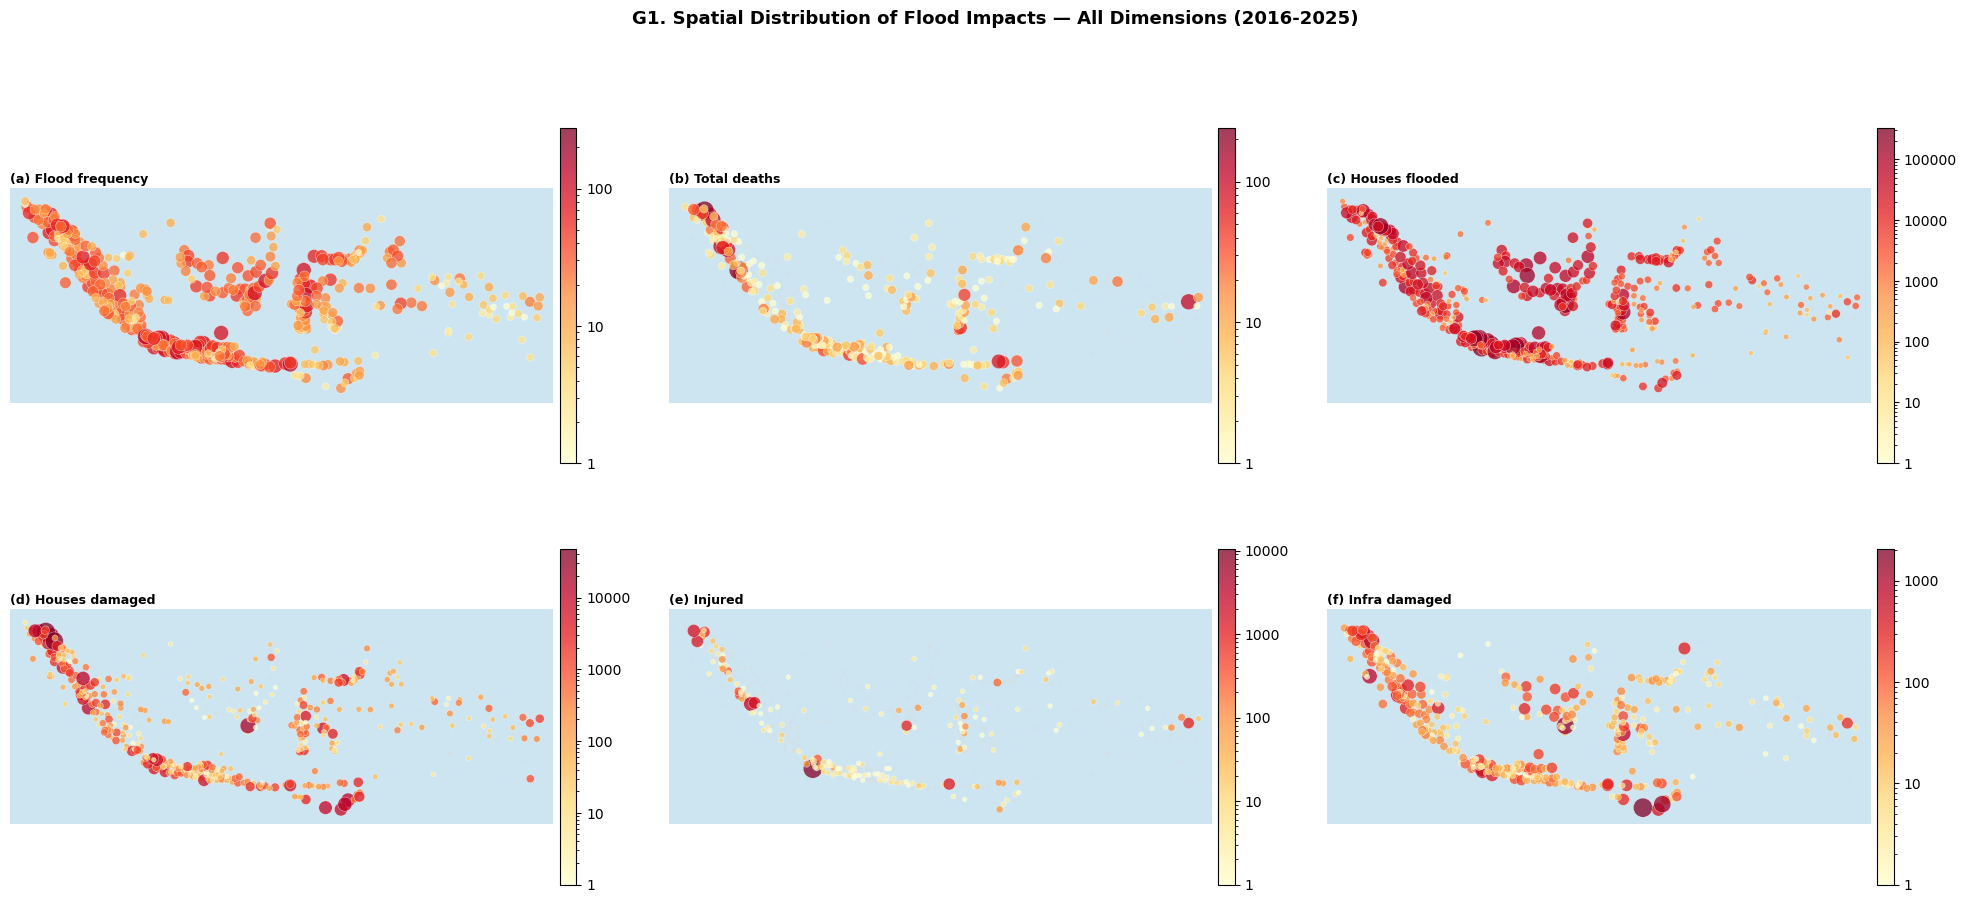

In [35]:
# ══════════════════════════════════════════════════════
# STEP 17 — Regency bubble maps by dimension
# ══════════════════════════════════════════════════════

reg_geo = df.groupby('bps_kab_code').agg(
    events        = ('Kejadian','count'),
    deaths        = ('Meninggal','sum'),
    house_flooded = ('Rumah Terendam','sum'),
    house_damaged = ('Rumah Rusak','sum'),
    injured       = ('Terluka','sum'),
    fasum         = ('Fasum Rusak','sum'),
).reset_index()
reg_geo = reg_geo.merge(cent[['bps_kab_code','centroid_lat','centroid_lon']],
                         on='bps_kab_code', how='inner')

def map_bg(ax, title):
    ax.set_xlim(94,142); ax.set_ylim(-12,7); ax.set_aspect('equal')
    ax.set_facecolor('#cce5f0')
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_title(title, fontsize=9, fontweight='bold', pad=4, loc='left')

map_cfgs = [
    ('events',       '(a) Flood frequency',    '#2171b5'),
    ('deaths',       '(b) Total deaths',        '#b2182b'),
    ('house_flooded','(c) Houses flooded',      '#4393c3'),
    ('house_damaged','(d) Houses damaged',      '#d6604d'),
    ('injured',      '(e) Injured',             '#f4a582'),
    ('fasum',        '(f) Infra damaged',       '#92c5de'),
]

plt.ioff()
fig, axes = plt.subplots(2, 3, figsize=(20, 10))
fig.suptitle('G1. Spatial Distribution of Flood Impacts — All Dimensions (2016-2025)',
             fontsize=13, fontweight='bold')

for ax, (col, title, color) in zip(axes.flat, map_cfgs):
    map_bg(ax, title)
    vals = reg_geo[col].values
    # Non-zero only
    mask_z = vals == 0
    mask_nz = vals > 0
    ax.scatter(reg_geo['centroid_lon'][mask_z],
               reg_geo['centroid_lat'][mask_z],
               s=6, c='#ddd', alpha=0.4, zorder=2, linewidths=0)
    if mask_nz.sum() > 0:
        sizes = (np.sqrt(vals[mask_nz]) /
                 np.sqrt(vals[mask_nz].max()) * 180 + 10)
        sc = ax.scatter(reg_geo['centroid_lon'][mask_nz],
                        reg_geo['centroid_lat'][mask_nz],
                        s=sizes, c=vals[mask_nz],
                        cmap='YlOrRd', norm=LogNorm(
                            vmin=max(1,vals[mask_nz].min()),
                            vmax=vals[mask_nz].max()),
                        alpha=0.75, zorder=4,
                        linewidths=0.3, edgecolors='white')
        fig.colorbar(sc, ax=ax, shrink=0.65, pad=0.01, format='%.0f')

plt.tight_layout(); plt.ion(); plt.show()


## STEP 18 — Composite flood-burden choropleth

Composite flood-burden choropleth (uses the Notebook 2 GeoPackage when available).

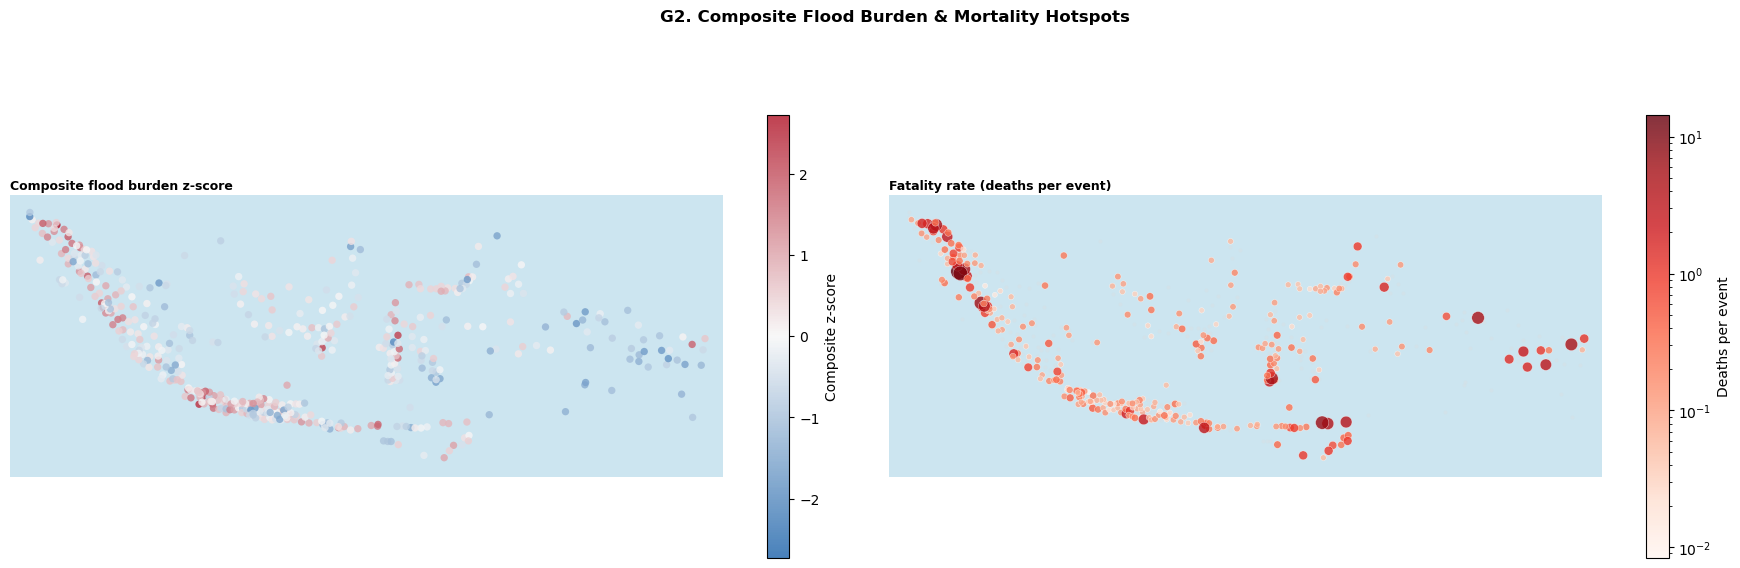

In [37]:
# ══════════════════════════════════════════════════════
# STEP 18 — Composite flood-burden choropleth
# ══════════════════════════════════════════════════════

z_ = lambda x: (x-x.mean())/(x.std()+1e-10)
reg_geo['HCI'] = (np.log1p(reg_geo['deaths']) + np.log1p(reg_geo['injured']))
reg_geo['PDI'] = np.log1p(reg_geo['house_flooded']) + np.log1p(reg_geo['house_damaged'])
reg_geo['composite'] = (z_(np.log1p(reg_geo['events'])) +
                         z_(reg_geo['HCI']) + z_(reg_geo['PDI'])) / 3

plt.ioff()
fig, axes = plt.subplots(1, 2, figsize=(18, 6.5))
fig.suptitle('G2. Composite Flood Burden & Mortality Hotspots',
             fontsize=12, fontweight='bold')

# Composite score
ax_l = axes[0]
map_bg(ax_l, 'Composite flood burden z-score')
cmap_div = LinearSegmentedColormap.from_list('div',['#2166ac','#f7f7f7','#b2182b'])
vmax_c = max(abs(reg_geo['composite'].min()), abs(reg_geo['composite'].max()))
sc_l = ax_l.scatter(reg_geo['centroid_lon'], reg_geo['centroid_lat'],
                    c=reg_geo['composite'],
                    cmap=cmap_div, vmin=-vmax_c, vmax=vmax_c,
                    s=28, alpha=0.82, linewidths=0)
fig.colorbar(sc_l, ax=ax_l, shrink=0.75, label='Composite z-score')

# Deaths per event (fatality rate)
ax_r = axes[1]
map_bg(ax_r, 'Fatality rate (deaths per event)')
reg_geo['fatality_rate'] = reg_geo['deaths'] / (reg_geo['events'] + 1)
fr = reg_geo['fatality_rate'].values
mask_fr = fr > 0
ax_r.scatter(reg_geo['centroid_lon'][~mask_fr], reg_geo['centroid_lat'][~mask_fr],
             s=8, c='#ddd', alpha=0.3, linewidths=0, zorder=2)
sc_r = ax_r.scatter(reg_geo['centroid_lon'][mask_fr], reg_geo['centroid_lat'][mask_fr],
                    c=fr[mask_fr], cmap='Reds',
                    norm=LogNorm(vmin=max(0.001,fr[mask_fr].min()),vmax=fr[mask_fr].max()),
                    s=np.sqrt(fr[mask_fr]/fr[mask_fr].max())*120+10,
                    alpha=0.80, linewidths=0.3, edgecolors='white', zorder=4)
fig.colorbar(sc_r, ax=ax_r, shrink=0.75, label='Deaths per event')

plt.tight_layout(); plt.ion(); plt.show()


## STEP 19 — Province-level time series

Annual flood counts for the most affected provinces, with a per-year contribution heatmap.

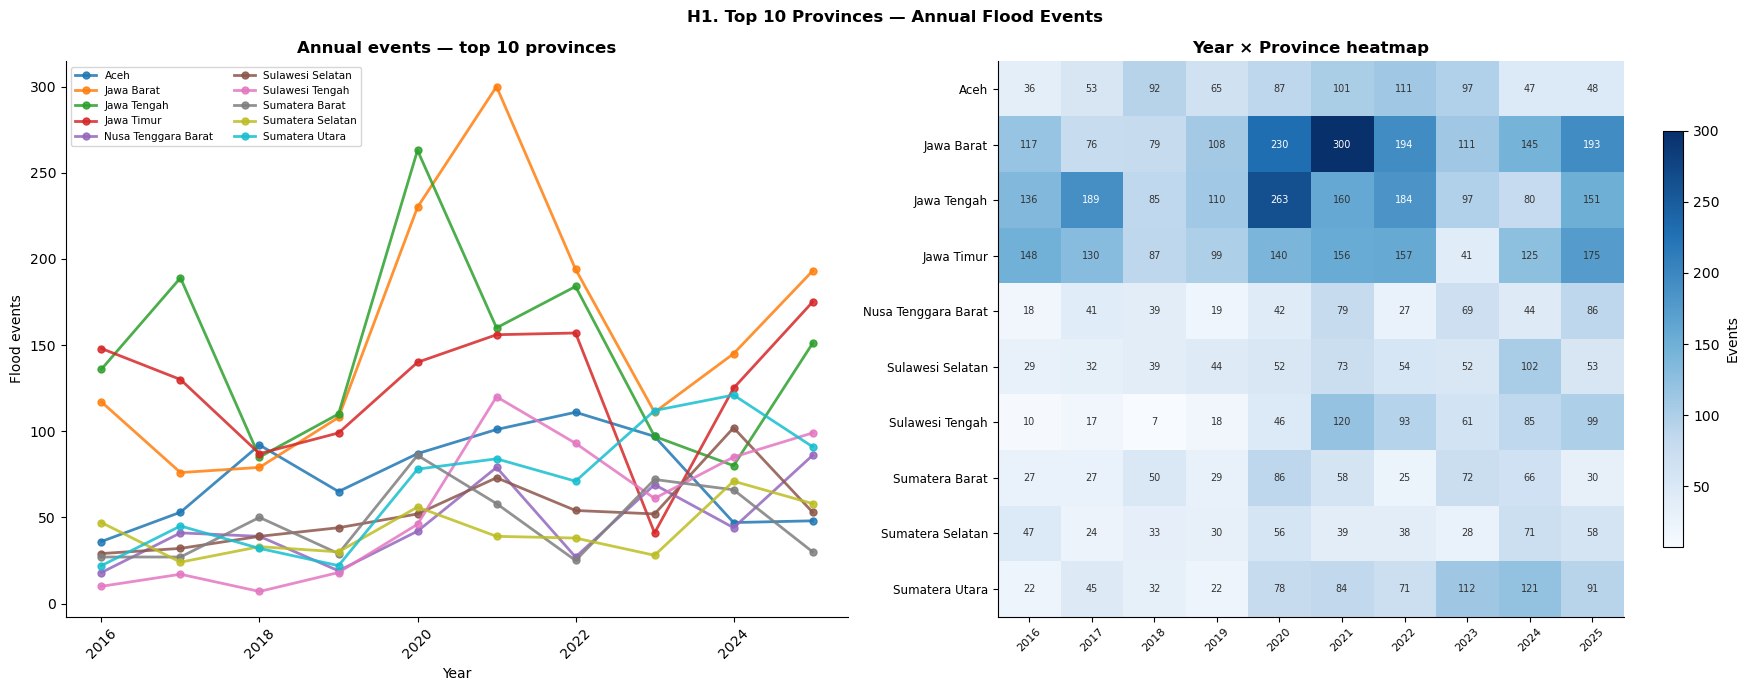

In [39]:
# ══════════════════════════════════════════════════════
# STEP 19 — Province-level time series
# ══════════════════════════════════════════════════════

top10_prov = (df.groupby('bps_prov_name')['Kejadian'].count()
              .nlargest(10).index.tolist())

prov_yr = (df[df['bps_prov_name'].isin(top10_prov)]
           .groupby(['bps_prov_name','year'])['Kejadian'].count()
           .reset_index().pivot(index='bps_prov_name', columns='year',
                                values='Kejadian').fillna(0))

plt.ioff()
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle('H1. Top 10 Provinces — Annual Flood Events',
             fontsize=12, fontweight='bold')

# Line chart
cmap_lines = cm.get_cmap('tab10', 10)
ax_l = axes[0]
for i, prov_name in enumerate(prov_yr.index):
    ax_l.plot(YEARS, prov_yr.loc[prov_name], 'o-',
              color=cmap_lines(i), lw=2, markersize=5,
              label=prov_name, alpha=0.85)
ax_l.set_xlabel('Year'); ax_l.set_ylabel('Flood events')
ax_l.set_title('Annual events — top 10 provinces', fontweight='bold')
ax_l.legend(fontsize=7.5, ncol=2, loc='upper left')
ax_l.tick_params(axis='x', rotation=45)

# Heatmap
ax_r = axes[1]
cmap_h2 = LinearSegmentedColormap.from_list('prov_heat',
    ['#f7fbff','#c6dbef','#6baed6','#2171b5','#08306b'])
im2 = ax_r.imshow(prov_yr.values, cmap=cmap_h2, aspect='auto')
ax_r.set_xticks(range(len(YEARS))); ax_r.set_xticklabels(YEARS, rotation=45, fontsize=8)
ax_r.set_yticks(range(len(prov_yr.index)))
ax_r.set_yticklabels(prov_yr.index, fontsize=8.5)
for i in range(len(prov_yr.index)):
    for j in range(len(YEARS)):
        v = int(prov_yr.values[i,j])
        ax_r.text(j, i, str(v), ha='center', va='center', fontsize=7,
                  color='white' if v > prov_yr.values.max()*0.6 else '#333')
fig.colorbar(im2, ax=ax_r, shrink=0.75, label='Events')
ax_r.set_title('Year × Province heatmap', fontweight='bold')

plt.tight_layout(); plt.ion(); plt.show()


## STEP 20 — Summary of key data facts

Key data facts compiled for use in the manuscript.

In [41]:
# ══════════════════════════════════════════════════════
# STEP 20 — Summary of key data facts
# ══════════════════════════════════════════════════════

total_events  = len(df)
total_deaths  = df['Meninggal'].sum()
total_flooded = df['Rumah Terendam'].sum()
peak_year     = annual.loc[annual['events'].idxmax(), 'year']
peak_events   = annual['events'].max()
worst_month   = MONTHS[monthly.loc[monthly['events'].idxmax(), 'month']-1]
deadliest_yr  = annual.loc[annual['deaths'].idxmax(), 'year']
top_prov      = df.groupby('bps_prov_name')['Kejadian'].count().idxmax()
jawa_pct      = df[df['island']=='Jawa']['Kejadian'].count() / total_events * 100
fatal_pct     = (df['Meninggal']>0).mean()*100
zero_impact   = (df[NUM_COLS].sum(axis=1)==0).mean()*100

print('=' * 65)
print('KEY DATASET FACTS — BNPB Flood Events 2016-2025')
print('=' * 65)
print(f'''
  Total flood records       : {total_events:,}
  Regencies covered         : {df['bps_kab_code'].nunique()} / 514
  Provinces                 : 38
  Study period              : 2016–2025 (10 years)

  Total deaths              : {total_deaths:,}
  Total houses flooded      : {total_flooded:,}

  Peak year (most events)   : {peak_year} ({peak_events:,} events)
  Deadliest year            : {deadliest_yr}
  Peak month                : {worst_month} (wet season peak)
  Most-affected province    : {top_prov}
  Jawa share of events      : {jawa_pct:.1f}%

  Events with any deaths    : {fatal_pct:.1f}%
  Events with zero impact   : {zero_impact:.1f}%
  (zero-inflation: main reason log(x+1) transform is used)

  KEY CORRELATION FINDING:
  Deaths vs Houses Flooded  : r = {stats.pearsonr(np.log1p(df["Meninggal"]), np.log1p(df["Rumah Terendam"]))[0]:.3f}
  (near-zero: justifies separating HCI and PDI into different composites)
''')


KEY DATASET FACTS — BNPB Flood Events 2016-2025

  Total flood records       : 13,030
  Regencies covered         : 502 / 514
  Provinces                 : 38
  Study period              : 2016–2025 (10 years)

  Total deaths              : 3,044
  Total houses flooded      : 8,177,967

  Peak year (most events)   : 2021 (1,916 events)
  Deadliest year            : 2025
  Peak month                : Jan (wet season peak)
  Most-affected province    : Jawa Barat
  Jawa share of events      : 35.7%

  Events with any deaths    : 5.3%
  Events with zero impact   : 11.3%
  (zero-inflation: main reason log(x+1) transform is used)

  KEY CORRELATION FINDING:
  Deaths vs Houses Flooded  : r = 0.003
  (near-zero: justifies separating HCI and PDI into different composites)

